# Feature Importance and Missing Data: An Empirical Comparison of Imputation Methods for Tabular Classification

Dataset breakdown
No.	Dataset	Experimental group
1	Breast Cancer Wisconsin	 - Controlled missingness
2	Banknote Authentication	- Controlled missingness
3	Digits	- Controlled missingness
4	Spambase -	Controlled missingness
5	MAGIC Gamma Telescope -	Controlled missingness
6	Ionosphere	 - Controlled missingness
7	Phoneme - 	Controlled missingness
8	Adult Census Income	 - Natural missingness
9	Horse Colic -	Natural missingness
10	Credit Approval	- Natural missingness

## 1. Setup and Configuration

**Execution:** There is no notebook elapsed-time cutoff. Every planned experiment is attempted until the loops finish, you interrupt execution, or the platform ends the session.

**Saved output:** Completed evaluations are checkpointed to disk immediately. Tables, figures, configuration, and metadata are saved under `/kaggle/working/study_results/<run-id>/`. A ZIP appears in `/kaggle/working/imputation_study_<run-id>.zip` and is refreshed at experiment-stage boundaries, after a manual interruption of an experiment stage, and after the final findings. An abrupt platform shutdown may prevent the latest ZIP refresh; the individual checkpoints remain the latest disk records.

**Resume:** The same output directory automatically reuses completed checkpoints. For a new Kaggle session, retain the previous outputs, attach them as input, and set `RESUME_FROM` to the exported ZIP or its `study_results/<run-id>` directory. The dataset contents, settings, and package versions must match. Kaggle working files need to be retained outside an ended session for cross-session recovery.


In [5]:
import os, sys, json, time, random, hashlib, warnings, logging, importlib, importlib.metadata
from pathlib import Path
from itertools import combinations, product
import subprocess, zipfile, shutil

FAST_MODE = False
FULL_MODE = not FAST_MODE
assert FAST_MODE != FULL_MODE
INSTALL_MISSING_PACKAGES = False
ALLOW_OPENML = True                # explicitly opt in; attached data works offline
USE_GPU = True
INCLUDE_CATBOOST = False             # optional sensitivity classifier
RUN_CORE = True
RUN_MULTIMODEL = True
RUN_MISMATCH = True
RUN_NATURAL = True
RESUME_FROM = None  # Optional previous study_results/<run-id> directory or exported ZIP.
OUTPUT_ROOT = Path('/kaggle/working') if Path('/kaggle').exists() else Path.cwd()/'output'
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
SEED = 2026
N_JOBS = min(4, os.cpu_count() or 2)
CODE_VERSION = '1.0.0'
MAIN_MODEL = 'hgb' if FAST_MODE else 'xgb'  # fallback is recorded as hgb
MAX_ROWS = 600 if FAST_MODE else 1500 # deterministic stratified subsampling
FOLDS = 2 if FAST_MODE else 3
REPEATS = 1 if FAST_MODE else 2
MASK_SEEDS = [17] if FAST_MODE else [17, 47]
MAX_DATASETS = 3 if FAST_MODE else 7
BOOTSTRAPS = 300 if FAST_MODE else 2000
PRACTICAL_DROP = .01                 # one macro-F1 percentage point
ALPHA = .05
MIN_INFERENCE_DATASETS = 5
START_TIME = time.monotonic()

PACKAGE_MAP = {'numpy':'numpy', 'pandas':'pandas', 'scipy':'scipy',
               'sklearn':'scikit-learn>=1.3,<2', 'matplotlib':'matplotlib',
               'seaborn':'seaborn', 'tqdm':'tqdm', 'xgboost':'xgboost>=2,<4',
               'torch':'torch', 'statsmodels':'statsmodels>=0.14,<1'}
if INSTALL_MISSING_PACKAGES:
    missing = [spec for module, spec in PACKAGE_MAP.items()
               if importlib.util.find_spec(module) is None]
    if missing:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])

import numpy as np
import pandas as pd
import scipy
from scipy.special import expit
from scipy.stats import friedmanchisquare, wilcoxon, spearmanr, norm, studentized_range
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import __version__ as SKLEARN_VERSION
from sklearn.datasets import load_breast_cancer, load_wine, load_digits, fetch_openml
from sklearn.model_selection import (RepeatedStratifiedKFold, train_test_split,
                                     KFold, cross_val_score)
from sklearn.preprocessing import LabelEncoder, StandardScaler, OneHotEncoder
from sklearn.inspection import permutation_importance
from sklearn.feature_selection import mutual_info_classif
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import SimpleImputer, KNNImputer, IterativeImputer
from sklearn.linear_model import BayesianRidge, LogisticRegression, Ridge
from sklearn.ensemble import (RandomForestClassifier, RandomForestRegressor,
                              HistGradientBoostingClassifier)
from sklearn.metrics import (accuracy_score, f1_score, balanced_accuracy_score,
                             roc_auc_score, r2_score)
from sklearn.pipeline import make_pipeline
from threadpoolctl import threadpool_limits
try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(it, **kwargs): return it
try:
    from IPython.display import display, Markdown, FileLink
except ImportError:
    display = print
    Markdown = str
    FileLink = str
try:
    import xgboost as xgb
except ImportError:
    xgb = None
try:
    import torch
except ImportError:
    torch = None
try:
    import statsmodels.formula.api as smf
except ImportError:
    smf = None
try:
    from catboost import CatBoostClassifier
except ImportError:
    CatBoostClassifier = None

logging.basicConfig(level=logging.INFO, format='%(asctime)s %(levelname)s %(message)s',
                    force=True)
log = logging.getLogger('missingness-study')
warnings.filterwarnings('once')
np.random.seed(SEED); random.seed(SEED)
if torch is not None:
    torch.manual_seed(SEED)
    torch.set_num_threads(N_JOBS)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
try:
    gpu_info = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total',
                               '--format=csv,noheader'], capture_output=True,
                              text=True, timeout=10)
    NVIDIA_AVAILABLE = gpu_info.returncode == 0 and bool(gpu_info.stdout.strip())
except (OSError, subprocess.TimeoutExpired):
    gpu_info = None; NVIDIA_AVAILABLE = False
GPU_AVAILABLE = USE_GPU and (NVIDIA_AVAILABLE or (torch is not None and torch.cuda.is_available()))
TORCH_DEVICE = 'cuda' if USE_GPU and torch is not None and torch.cuda.is_available() else 'cpu'
if MAIN_MODEL == 'xgb' and xgb is None:
    log.warning('XGBoost unavailable; actual primary classifier is HGB.')
    MAIN_MODEL = 'hgb'
VERSIONS = {'python':sys.version.split()[0], 'numpy':np.__version__,
            'pandas':pd.__version__, 'scipy':scipy.__version__,
            'sklearn':SKLEARN_VERSION, 'xgboost':getattr(xgb,'__version__','unavailable'),
            'torch':getattr(torch,'__version__','unavailable'),
            'statsmodels':importlib.metadata.version('statsmodels') if smf else 'unavailable'}
print('Versions:', json.dumps(VERSIONS, indent=2))
print('GPU:', gpu_info.stdout.strip() if NVIDIA_AVAILABLE else ('CUDA detected via PyTorch' if GPU_AVAILABLE else 'CPU fallback'),
      '| PyTorch device:', TORCH_DEVICE)
sns.set_theme(style='whitegrid', context='notebook')
_thread_limit = threadpool_limits(limits=N_JOBS)
INPUT_ROOT = Path('/kaggle/input')
pd.set_option('display.max_rows',200); pd.set_option('display.max_columns',60); pd.set_option('display.width',220)
IMPUTERS = ['mean', 'median', 'mode', 'median_indicator', 'knn', 'iterative', 'rf_iterative', 'native']
METRICS_HIGH = ['accuracy','macro_f1','balanced_accuracy','roc_auc','minority_f1']
METRICS_LOW = ['brier','ece']

def stable_seed(*parts):
    """Order-independent-of-execution deterministic seed; never use Python hash()."""
    return int(hashlib.sha256(json.dumps(parts, default=json_scalar).encode()).hexdigest()[:8],16)

def json_scalar(value):
    """Canonicalize NumPy scalar types so cached and uncached seeds are identical."""
    return value.item() if isinstance(value,np.generic) else str(value)

TABLES = {}
_OUTPUT_DIRECTORY = None

def atomic_csv(frame, path):
    """Write complete CSVs before replacing an existing output/checkpoint."""
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + '.tmp')
    frame.to_csv(temporary, index=False)
    os.replace(temporary, path)

def atomic_json(value, path):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + '.tmp')
    temporary.write_text(json.dumps(value, indent=2, default=json_scalar), encoding='utf-8')
    os.replace(temporary, path)

def read_csv_safe(path):
    try:
        return pd.read_csv(path)
    except (FileNotFoundError, pd.errors.EmptyDataError):
        return pd.DataFrame()

def keep(name, frame):
    """Retain a result table in memory and export its full-precision CSV."""
    TABLES[name] = frame
    if _OUTPUT_DIRECTORY is not None:
        atomic_csv(frame, _OUTPUT_DIRECTORY / f'{name}.csv')
    return frame

def kept(name):
    if name not in TABLES and _OUTPUT_DIRECTORY is not None:
        TABLES[name] = read_csv_safe(_OUTPUT_DIRECTORY / f'{name}.csv')
    return TABLES.get(name, pd.DataFrame())


Versions: {
  "python": "3.13.15",
  "numpy": "2.1.3",
  "pandas": "2.3.3",
  "scipy": "1.16.3",
  "sklearn": "1.6.1",
  "xgboost": "3.4.1",
  "torch": "2.11.0+cu128",
  "statsmodels": "0.15.0"
}
GPU: Tesla T4, 15360 MiB
Tesla T4, 15360 MiB | PyTorch device: cuda


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 2. Datasets

In [6]:
DATASETS = {}
DATASET_AUDIT = []
FILE_OVERRIDES = {}                 # e.g. {'spambase':'/kaggle/input/.../spambase.data'}
ATTACHED = sorted([p for p in INPUT_ROOT.rglob('*') if p.is_file()]) if INPUT_ROOT.exists() else []

def find_input(name, tokens, suffixes=('.csv','.data','.txt')):
    """Find a registered input unambiguously; reject competing candidates."""
    if name in FILE_OVERRIDES: return Path(FILE_OVERRIDES[name])
    candidates = [p for p in ATTACHED if p.suffix.lower() in suffixes
                  and any(t.lower() in str(p).lower() for t in tokens)
                  and not any(t in p.name.lower() for t in ['names','metadata','readme','test'])]
    if len(candidates)>1:
        preferred = [p for p in candidates if p.suffix.lower()=='.csv']
        if len(preferred)==1: return preferred[0]
        raise ValueError(f'Ambiguous {name}: {[str(p) for p in candidates]}; set FILE_OVERRIDES.')
    return candidates[0] if candidates else None

def clean_frame(df):
    df = df.copy()
    df.columns = [str(c).strip().lower().replace('.','_').replace(' ','_') for c in df.columns]
    for c in df.select_dtypes(include=['object','string','category']):
        df[c] = df[c].astype(object).map(lambda v: v.strip() if isinstance(v,str) else v)
        df[c] = df[c].replace({'?':np.nan, '':np.nan})
        numeric = pd.to_numeric(df[c],errors='coerce')
        if numeric.notna().sum()==df[c].notna().sum(): df[c]=numeric
    return df.replace([np.inf,-np.inf],np.nan)

def drop_leading_index(df,n_expected):
    """Drop a leading row-index column that some CSV exports add (e.g. MAGIC)."""
    if df.shape[1]==n_expected+1:
        first=pd.to_numeric(df.iloc[:,0],errors='coerce')
        label=str(df.columns[0]).strip().lower()
        sequential=bool(first.notna().all() and len(first)>1 and (first.diff().dropna()==1).all())
        if label.startswith('unnamed') or label in ('','index','id') or sequential:
            return df.iloc[:,1:].reset_index(drop=True)
    return df

def read_registered(name, path):
    """Read known schemas; never guess a target column for arbitrary input files."""
    df = pd.read_csv(path, na_values=['?',' ?'], skipinitialspace=True)
    expected = {'banknote':5,'spambase':58,'magic':11}
    if name in expected:
        # Raw UCI .data and numeric/headerless CSV must retain the first observation.
        first_names_numeric = all(_is_number(c) for c in df.columns[:-1])
        if path.suffix.lower()=='.data' or first_names_numeric:
            df = pd.read_csv(path,header=None,na_values=['?'],skipinitialspace=True)
            df.columns=[f'x{i}' for i in range(df.shape[1]-1)]+['target']
        df=drop_leading_index(df,expected[name])
        if df.shape[1]!=expected[name]:
            raise ValueError(f'{name}: expected {expected[name]} columns, found {df.shape[1]}')
    df=clean_frame(df)
    targets={'banknote':['class','target'], 'spambase':['class','spam','target'],
             'magic':['class','target'], 'adult':['income'], 'pima':['outcome'], 'horse':['outcome']}
    target=next((c for c in targets[name] if c in df.columns), None)
    if target is None and name in expected: target=df.columns[-1]
    if target is None: raise ValueError(f'{name}: expected target {targets[name]}')
    y=df.pop(target)
    if name=='adult':
        y=y.map(lambda z: z.rstrip('.') if isinstance(z,str) else z)
    if name=='pima':
        for c in ['glucose','bloodpressure','skinthickness','insulin','bmi']:
            if c in df: df[c]=df[c].replace(0,np.nan)
    if name=='horse':
        # Outcome-adjacent variables are excluded from a pre-treatment prediction task.
        df=df.drop(columns=['hospital_number','surgical_lesion','lesion_1','lesion_2','lesion_3','cp_data'],errors='ignore')
        cats=['surgery','age','temp_of_extremities','peripheral_pulse','mucous_membrane',
              'capillary_refill_time','pain','peristalsis','abdominal_distention',
              'nasogastric_tube','nasogastric_reflux','rectal_exam_feces','abdomen',
              'abdomo_appearance']
        for c in cats:
            if c in df:
                df[c]=df[c].map(lambda v: np.nan if pd.isna(v) else f'{c}={v}')
    return df,y

def _is_number(x):
    try: float(str(x)); return True
    except ValueError: return False

def register_dataset(name, X, y, group, source, fingerprint=None):
    """Apply uniform rules before deterministic row-capping; save exclusion reasons."""
    X=clean_frame(pd.DataFrame(X)); y=pd.Series(y).reset_index(drop=True)
    X=X.reset_index(drop=True)
    valid=y.notna(); X=X.loc[valid].reset_index(drop=True); y=y.loc[valid].reset_index(drop=True)
    joined=X.copy(); joined['__label__']=y
    unique=~joined.duplicated(); duplicates=int((~unique).sum())
    X=X.loc[unique].reset_index(drop=True); y=y.loc[unique].reset_index(drop=True)
    original_n=len(X); numeric=list(X.select_dtypes(include='number').columns)
    reasons=[]
    minimum_rows=300 if group=='A' else 100
    if len(X)<minimum_rows: reasons.append(f'fewer than {minimum_rows} rows for Group {group}')
    if not 3<=X.shape[1]<=100: reasons.append('feature count outside 3..100')
    if y.nunique()<2 or y.nunique()>30: reasons.append('not an eligible classification target')
    if y.value_counts().min()<max(FOLDS,4): reasons.append('insufficient class support')
    if group=='A' and (X.isna().any().any() or y.isna().any()): reasons.append('missing values in Group A')
    if group=='A' and len(numeric)/X.shape[1]<.8: reasons.append('less than 80% numeric')
    if group=='B' and not X.isna().any().any(): reasons.append('no natural missingness')
    DATASET_AUDIT.append({'dataset':name,'group':group,'original_rows':original_n,
                          'duplicates_removed':duplicates,'status':'excluded' if reasons else 'included',
                          'reason':'; '.join(reasons),'source':source})
    if reasons: return
    if len(X)>MAX_ROWS:
        chosen,_=train_test_split(np.arange(len(X)), train_size=MAX_ROWS,
                                   stratify=y, random_state=SEED)
        chosen=np.sort(chosen); X=X.iloc[chosen].reset_index(drop=True); y=y.iloc[chosen].reset_index(drop=True)
    enc=LabelEncoder(); yy=enc.fit_transform(y.astype(str))
    data_hash=hashlib.sha256(pd.util.hash_pandas_object(X,index=True).values.tobytes()+yy.tobytes()).hexdigest()
    DATASETS[name]={'X':X,'y':yy,'group':group,'source':source,'original_rows':original_n,
                    'labels':enc.classes_.tolist(),'fingerprint':data_hash,
                    'input_sha256':fingerprint,'numeric':numeric,
                    'categorical':[c for c in X if c not in numeric]}

for name, loader in [('breast_cancer',load_breast_cancer),('wine',load_wine),('digits',load_digits)]:
    d=loader(as_frame=True)
    register_dataset(name,d.data,d.target,'A',f'sklearn.{loader.__name__}')
REGISTRY = [
    ('banknote','A',['banknote','bank-note-authentication']),
    ('spambase','A',['spambase']),
    ('magic','A',['magic-gamma','magic04','magic_gamma']),
    ('adult','B',['adult-census','adult.csv']),
    ('pima','B',['pima-indians','diabetes.csv']),
    ('horse','B',['horse-colic','horse.csv'])]
for name,group,tokens in REGISTRY:
    try:
        path=find_input(name,tokens)
        if path is None:
            DATASET_AUDIT.append({'dataset':name,'group':group,'status':'unavailable',
                                  'reason':'attach registered Kaggle dataset','source':'Kaggle'})
            continue
        X,y=read_registered(name,path)
        register_dataset(name,X,y,group,str(path),hashlib.sha256(path.read_bytes()).hexdigest())
    except Exception as e:
        log.warning('Dataset %s skipped: %s',name,e)
        DATASET_AUDIT.append({'dataset':name,'group':group,'status':'failed','reason':str(e),'source':'Kaggle'})
if ALLOW_OPENML:
    # fetch_openml has bounded retries; disabled by default to avoid blocked-network stalls.
    for name, data_id, group in [('ionosphere',59,'A'),('phoneme',1489,'A'),('credit_approval',29,'B')]:
        if name in DATASETS: continue
        try:
            d=fetch_openml(data_id=data_id,as_frame=True,n_retries=1,delay=.1)
            register_dataset(name,d.data,d.target,group,f'https://www.openml.org/d/{data_id}')
        except Exception as e: log.warning('OpenML %s unavailable: %s',name,e)
order=['breast_cancer','banknote','digits','spambase','magic','ionosphere','phoneme']
GROUP_A=[n for n in order if n in DATASETS and DATASETS[n]['group']=='A'][:MAX_DATASETS]
GROUP_B=[n for n,d in DATASETS.items() if d['group']=='B']
if FAST_MODE and len(GROUP_A)<3:
    log.warning('FAST requested 3 datasets, but only %s eligible inputs are available. Attach Banknote; no data are fabricated.',len(GROUP_A))

def dataset_summary(name,d):
    num=d['X'][d['numeric']]
    corr=num.corr().abs().to_numpy(); vals=corr[np.triu_indices(len(corr),1)]
    counts=np.bincount(d['y']); balance=counts/counts.sum()
    return {'dataset':name,'group':d['group'],'rows':len(d['X']),
            'original_rows':d['original_rows'],'features':d['X'].shape[1],
            'classes':len(counts),'class_balance':json.dumps(dict(zip(d['labels'],balance.round(4).tolist()))),
            'numeric':len(d['numeric']),'categorical':len(d['categorical']),
            'mean_abs_correlation':float(np.nanmean(vals)) if np.isfinite(vals).any() else np.nan,
            'missing_fraction':float(d['X'].isna().to_numpy().mean()),'source':d['source']}
SUMMARY=pd.DataFrame([dataset_summary(n,d) for n,d in DATASETS.items() if n in GROUP_A+GROUP_B])
display(SUMMARY); display(pd.DataFrame(DATASET_AUDIT))
assert GROUP_A, 'No eligible complete dataset available.'

,dataset,group,rows,original_rows,features,classes,class_balance,numeric,categorical,mean_abs_correlation,missing_fraction,source
0,breast_cancer,A,569,569,30,2,"{""0"": 0.3726, ""1"": 0.6274}",30,0,0.394897,0.000000,sklearn.load_breast_cancer
1,digits,A,1500,1797,64,10,"{""0"": 0.0993, ""1"": 0.1013, ""2"": 0.0987, ""3"": 0...",64,0,0.123941,0.000000,sklearn.load_digits
2,banknote,A,1348,1348,4,2,"{""0"": 0.5475, ""1"": 0.4525}",4,0,0.425179,0.000000,/kaggle/input/datasets/ritesaluja/bank-note-au...
3,spambase,A,1500,4210,57,2,"{""0"": 0.6013, ""1"": 0.3987}",57,0,0.060428,0.000000,/kaggle/input/datasets/colormap/spambase/spamb...
4,magic,A,1500,18905,10,2,"{""g"": 0.652, ""h"": 0.348}",10,0,0.266117,0.000000,/kaggle/input/datasets/abhinavmangalore/magic-...
5,adult,B,1500,32537,14,2,"{""<=50K"": 0.7593, "">50K"": 0.2407}",6,8,0.058827,0.008048,/kaggle/input/datasets/uciml/adult-census-inco...
6,horse,B,291,291,21,3,"{""died"": 0.2543, ""euthanized"": 0.1478, ""lived""...",7,14,0.212501,0.254623,/kaggle/input/datasets/uciml/horse-colic/horse...
7,ionosphere,A,350,350,34,2,"{""b"": 0.3571, ""g"": 0.6429}",34,0,0.230452,0.000000,https://www.openml.org/d/59
8,phoneme,A,1500,5395,5,2,"{""1"": 0.708, ""2"": 0.292}",5,0,0.129303,0.000000,https://www.openml.org/d/1489
9,credit_approval,B,690,690,15,2,"{""+"": 0.4449, ""-"": 0.5551}",6,9,0.166753,0.006473,https://www.openml.org/d/29


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,dataset,group,original_rows,duplicates_removed,status,reason,source
0,breast_cancer,A,569,0,included,,sklearn.load_breast_cancer
1,wine,A,178,0,excluded,fewer than 300 rows for Group A,sklearn.load_wine
2,digits,A,1797,0,included,,sklearn.load_digits
3,banknote,A,1348,24,included,,/kaggle/input/datasets/ritesaluja/bank-note-au...
4,spambase,A,4210,391,included,,/kaggle/input/datasets/colormap/spambase/spamb...
5,magic,A,18905,115,included,,/kaggle/input/datasets/abhinavmangalore/magic-...
6,adult,B,32537,24,included,,/kaggle/input/datasets/uciml/adult-census-inco...
7,pima,B,768,0,excluded,no natural missingness,/kaggle/input/datasets/jamaltariqcheema/pima-i...
8,horse,B,291,8,included,,/kaggle/input/datasets/uciml/horse-colic/horse...
9,ionosphere,A,350,1,included,,https://www.openml.org/d/59


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 3. Feature Importance and Redundancy

In [7]:
class FoldEncoder:
    """Training-only categorical vocabularies, keeping feature identities and NaNs."""
    def fit(self,X):
        self.columns=list(X.columns)
        self.cat_idx=[i for i,c in enumerate(X) if not pd.api.types.is_numeric_dtype(X[c])]
        self.num_idx=[i for i in range(X.shape[1]) if i not in self.cat_idx]
        self.maps={i:{v:j for j,v in enumerate(sorted(X.iloc[:,i].dropna().astype(str).unique()))}
                   for i in self.cat_idx}
        return self
    def transform(self,X):
        A=np.empty(X.shape,dtype=float)
        for i,c in enumerate(self.columns):
            if i in self.cat_idx:
                # Unknown observed levels use -1; actual missing values remain NaN.
                s=X[c]; A[:,i]=s.map(lambda v: np.nan if pd.isna(v) else self.maps[i].get(str(v),-1)).to_numpy()
            else: A[:,i]=pd.to_numeric(X[c],errors='coerce').to_numpy(float)
        return A

def training_importance(A,y,enc,seed):
    """Compute fold-level importance and tiers on an inner training/holdout split."""
    a,b=train_test_split(np.arange(len(y)),test_size=.25,stratify=y,random_state=seed)
    reference=RandomForestClassifier(n_estimators=60 if FAST_MODE else 100,
                                     max_depth=None,min_samples_leaf=2,n_jobs=N_JOBS,random_state=seed)
    reference.fit(A[a],y[a])
    pi=permutation_importance(reference,A[b],y[b],scoring='f1_macro',
                              n_repeats=3 if FAST_MODE else 5,random_state=seed,n_jobs=1)
    mi=mutual_info_classif(A[a],y[a],discrete_features=[i in enc.cat_idx for i in range(A.shape[1])],random_state=seed)
    eligible=[i for i in enc.num_idx if np.std(A[:,i])>1e-10]
    if len(eligible)<3: raise ValueError('Fewer than three varying numeric targets.')
    C=pd.DataFrame(A).corr().abs().fillna(0).to_numpy(copy=True); np.fill_diagonal(C,0)
    frame=pd.DataFrame({'feature_id':np.arange(A.shape[1]),'feature':enc.columns,
                        'permutation':pi.importances_mean,'permutation_sd':pi.importances_std,
                        'mutual_information':mi,'max_abs_corr':C.max(axis=1),
                        'importance_reference_f1':f1_score(y[b],reference.predict(A[b]),average='macro')})
    plans={}
    for basis,col in [('permutation','permutation'),('mi','mutual_information')]:
        ranked=sorted(eligible,key=lambda i:(-frame.loc[i,col],i))
        tiers=np.array_split(ranked,3)
        chosen={tier:int(ids[len(ids)//2]) for tier,ids in zip(['top','middle','bottom'],tiers)}
        plans[basis]=(ranked,chosen)
        for rank,i in enumerate(ranked):
            frame.loc[i,f'{basis}_rank']=1-rank/max(1,len(ranked)-1)
            frame.loc[i,f'{basis}_tier']=next(t for t,ids in zip(['top','middle','bottom'],tiers) if i in ids)
    selected=set(v for _,ts in plans.values() for v in ts.values())
    for j in selected:
        others=np.delete(A,j,axis=1)
        scores=cross_val_score(make_pipeline(StandardScaler(),Ridge(alpha=1.0)),others,A[:,j],
                               cv=KFold(3,shuffle=True,random_state=seed),scoring='r2',n_jobs=1)
        frame.loc[j,'redundancy_r2']=scores.mean()
    return frame,plans,C

## 4. Missingness Mechanism Generators

In [8]:
STRENGTHS={'mnar_mild':.75,'mnar_moderate':2.,'mnar_strong':6.}
MECHANISMS=['mcar','mar_redundant','mar_unrelated',*STRENGTHS,'mnar_censor','label']

def calibrate_intercept(scores,rate):
    """Bisection yielding training mean logistic probability equal to rate."""
    lo,hi=-80.,80.
    for _ in range(80):
        mid=(lo+hi)/2
        if expit(np.clip(scores+mid,-80,80)).mean()<rate: lo=mid
        else: hi=mid
    return (lo+hi)/2

class MaskGenerator:
    """Fit an observation process on training data, then sample any partition."""
    def __init__(self,mechanism,rate,target_cols,strength=None):
        self.mechanism=mechanism; self.rate=float(rate); self.cols=list(target_cols)
        self.strength=strength
    def fit(self,A,y,corr=None):
        if not 0<=self.rate<1: raise ValueError('rate must be in [0,1)')
        if not np.isfinite(A).all(): raise ValueError('Synthetic generator requires complete data.')
        self.p=A.shape[1]; self.target=self.cols[0]; self.driver=None; self.driver_corr=np.nan
        m=self.mechanism
        if m.startswith('mar_'):
            candidates=[j for j in range(self.p) if j not in self.cols and np.std(A[:,j])>1e-10]
            if not candidates: raise ValueError('No observed MAR driver.')
            C=pd.DataFrame(A).corr().abs().fillna(0).to_numpy() if corr is None else corr
            pick=max if m=='mar_redundant' else min
            self.driver=pick(candidates,key=lambda j:C[self.target,j])
            self.driver_corr=float(C[self.target,self.driver]); idx=self.driver
            self.mu=float(A[:,idx].mean()); self.sd=max(float(A[:,idx].std()),1e-8)
            self.slope=2.; scores=self.slope*(A[:,idx]-self.mu)/self.sd
            self.intercept=calibrate_intercept(scores,self.rate)
        elif m in STRENGTHS:
            idx=self.target; self.mu=float(A[:,idx].mean()); self.sd=max(float(A[:,idx].std()),1e-8)
            self.slope=STRENGTHS[m] if self.strength is None else self.strength
            self.intercept=calibrate_intercept(self.slope*(A[:,idx]-self.mu)/self.sd,self.rate)
        elif m=='label':
            counts=np.bincount(y); minority=int(counts.argmin())
            self.label_scores={int(c):(2.5 if c==minority else -.5) for c in np.unique(y)}
            self.intercept=calibrate_intercept(np.array([self.label_scores[int(c)] for c in y]),self.rate)
        elif m=='mnar_censor':
            values=A[:,self.target]; self.threshold=float(np.quantile(values,1-self.rate))
            above=np.mean(values>self.threshold); equal=np.mean(values==self.threshold)
            self.tie_probability=float(np.clip((self.rate-above)/max(equal,1e-12),0,1))
        elif m not in ['mcar','block_top','block_random']:
            raise ValueError(m)
        return self
    def probabilities(self,A,y):
        if self.rate==0: return np.zeros(len(A))
        m=self.mechanism
        if m.startswith('mar_'):
            return expit(self.intercept+self.slope*(A[:,self.driver]-self.mu)/self.sd)
        if m in STRENGTHS:
            return expit(self.intercept+self.slope*(A[:,self.target]-self.mu)/self.sd)
        if m=='label': return expit(self.intercept+np.array([self.label_scores.get(int(c),0) for c in y]))
        if m=='mnar_censor':
            v=A[:,self.target]
            return np.where(v>self.threshold,1.,np.where(v==self.threshold,self.tie_probability,0.))
        return np.full(len(A),self.rate)
    def sample(self,A,y,seed):
        rng=np.random.default_rng(seed); probs=self.probabilities(A,y)
        rows=rng.random(len(A))<probs
        mask=np.zeros(A.shape,dtype=bool); mask[:,self.cols]=rows[:,None]
        return mask,probs

def check_mask(mask,probs,generator,partition):
    realized=mask[:,generator.cols].mean()
    expected=probs.mean(); tolerance=4*np.sqrt(np.sum(probs*(1-probs)))/len(probs)+1/len(probs)
    return {'partition':partition,'requested_target_rate':generator.rate,
            'expected_target_rate':expected,'realized_target_rate':realized,
            'global_cell_rate':mask.mean(),'expected_global_rate':expected*len(generator.cols)/mask.shape[1],
            'sampling_tolerance':tolerance,'sampling_check':bool(abs(realized-expected)<=tolerance),
            'test_rate_drift':expected-generator.rate,'driver':generator.driver,
            'driver_abs_corr':generator.driver_corr,'masked_columns':len(generator.cols)}

def test_mask_generators():
    rng=np.random.default_rng(100); A=rng.normal(size=(20000,5)); A[:,1]=A[:,0]+rng.normal(0,.1,20000)
    y=(A[:,2]>0).astype(int); checks=[]
    for m,rate in product(MECHANISMS+['block_top','block_random'],[.1,.2,.4]):
        cols=[0,2] if m.startswith('block') else [0]
        g=MaskGenerator(m,rate,cols).fit(A,y)
        mask,probs=g.sample(A,y,10); same,_=g.sample(A,y,10)
        assert mask.dtype==bool and mask.shape==A.shape and np.array_equal(mask,same)
        assert not mask[:,[j for j in range(5) if j not in cols]].any()
        assert abs(probs.mean()-rate)<1e-6
        assert check_mask(mask,probs,g,'train')['sampling_check']
        if m.startswith('mar'): assert g.driver not in cols
        if m.startswith('block'): assert np.array_equal(mask[:,0],mask[:,2])
        if m in STRENGTHS: assert np.corrcoef(A[:,0],probs)[0,1]>0
        checks.append({'mechanism':m,**check_mask(mask,probs,g,'unit_test')})
    g=MaskGenerator('mnar_strong',.2,[0]).fit(A,y)
    before=json.dumps(g.__dict__,sort_keys=True)
    g.sample(A+50,y,20)
    assert json.dumps(g.__dict__,sort_keys=True)==before, 'Test transformation changed training parameters.'
    assert not MaskGenerator('mcar',0,[0]).fit(A,y).sample(A,y,0)[0].any()
    return pd.DataFrame(checks)
MASK_UNIT_CHECKS=test_mask_generators()
display(MASK_UNIT_CHECKS[['mechanism','requested_target_rate','realized_target_rate','sampling_check']])

,mechanism,requested_target_rate,realized_target_rate,sampling_check
0,mcar,0.1,0.09670,True
1,mcar,0.2,0.19900,True
2,mcar,0.4,0.40130,True
3,mar_redundant,0.1,0.10015,True
4,mar_redundant,0.2,0.19895,True
5,mar_redundant,0.4,0.39825,True
6,mar_unrelated,0.1,0.09925,True
7,mar_unrelated,0.2,0.19935,True
8,mar_unrelated,0.4,0.39575,True
9,mnar_mild,0.1,0.09805,True


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 5. Imputation Methods

In [9]:
class FoldImputer:
    """CPU imputation with fold-fitted scaling and categorical mode handling."""
    def __init__(self,method,enc,seed): self.method=method; self.enc=enc; self.seed=seed
    def fit(self,A):
        self.num=self.enc.num_idx; self.cat=self.enc.cat_idx
        self.mu=np.nanmean(A[:,self.num],axis=0); self.mu=np.nan_to_num(self.mu,nan=0.)
        self.sd=np.nanstd(A[:,self.num],axis=0); self.sd=np.where(np.isfinite(self.sd)&(self.sd>1e-8),self.sd,1.)
        self.cat_modes={}
        for j in self.cat:
            v=A[:,j][np.isfinite(A[:,j])]
            self.cat_modes[j]=float(pd.Series(v).mode().iloc[0]) if len(v) else 0.
        Z=(A[:,self.num]-self.mu)/self.sd
        method=self.method
        if method in ['native','complete']: self.estimator=None
        elif method in ['mean','median','mode','median_indicator']:
            strategy={'mode':'most_frequent','median_indicator':'median'}.get(method,method)
            self.estimator=SimpleImputer(strategy=strategy,keep_empty_features=True)
        elif method=='knn': self.estimator=KNNImputer(n_neighbors=5,weights='distance',keep_empty_features=True)
        elif method in ['iterative','rf_iterative']:
            estimator=BayesianRidge() if method=='iterative' else RandomForestRegressor(
                n_estimators=20 if FAST_MODE else 40,max_depth=8,min_samples_leaf=3,
                max_features=.8,n_jobs=N_JOBS,random_state=self.seed)
            self.estimator=IterativeImputer(estimator=estimator,max_iter=3 if FAST_MODE else 5,
                tol=.01,initial_strategy='median',skip_complete=bool(np.isnan(Z).any()),
                n_nearest_features=min(12,Z.shape[1]-1) if Z.shape[1]>1 else None,
                keep_empty_features=True,random_state=self.seed)
        else: raise ValueError(method)
        if self.estimator is not None:
            donors=Z
            cap=800 if FAST_MODE else 1000
            if method=='knn' and len(Z)>cap:
                donors=Z[np.random.default_rng(self.seed).choice(len(Z),cap,replace=False)]
            with warnings.catch_warnings(record=True) as captured:
                warnings.simplefilter('always')
                self.estimator.fit(donors)
            self.fit_warning=' | '.join(sorted(set(str(w.message) for w in captured)))
        else: self.fit_warning=''
        return self
    def transform(self,A):
        B=A.copy(); Z=(A[:,self.num]-self.mu)/self.sd
        if self.estimator is not None: Z=self.estimator.transform(Z)
        B[:,self.num]=Z*self.sd+self.mu
        if self.method not in ['native','complete']:
            for j in self.cat: B[:,j]=np.where(np.isnan(B[:,j]),self.cat_modes[j],B[:,j])
        indicators=np.isnan(A).astype(float) if self.method=='median_indicator' else None
        return B,indicators

class ModelEncoder:
    """One-hot categorical levels from training vocabulary; native NaNs preserved."""
    def __init__(self,enc): self.enc=enc
    def transform(self,A,indicators=None):
        pieces=[A[:,self.enc.num_idx]]
        for j in self.enc.cat_idx:
            K=max(1,len(self.enc.maps[j])); v=A[:,j]
            z=(v[:,None]==np.arange(K)[None,:]).astype(float)
            z[np.isnan(v)]=np.nan
            pieces.append(z)
        if indicators is not None: pieces.append(indicators)
        return np.concatenate(pieces,axis=1).astype(np.float32)

def reconstruction_rmse(truth,reconstructed,mask,num_idx,training_sd):
    """Test RMSE only on artificially masked numeric cells, raw and standardized."""
    if not mask[:,num_idx].any(): return np.nan,np.nan
    err=(reconstructed[:,num_idx]-truth[:,num_idx]); selected=mask[:,num_idx]
    return float(np.sqrt(np.mean(err[selected]**2))),float(np.sqrt(np.mean((err/training_sd)[selected]**2)))

## 6. Models and Training Pipeline

In [10]:
class TorchMLP:
    """Small fixed-epoch classifier; no validation/test labels enter training."""
    def __init__(self,seed,device=TORCH_DEVICE): self.seed=seed; self.device=device
    def fit(self,X,y):
        torch.manual_seed(self.seed)
        if self.device=='cuda': torch.cuda.manual_seed_all(self.seed)
        self.classes_=np.unique(y); self.scaler=StandardScaler().fit(X)
        T=torch.tensor(self.scaler.transform(X),dtype=torch.float32,device=self.device)
        Y=torch.tensor(y,dtype=torch.long,device=self.device)
        self.net=torch.nn.Sequential(torch.nn.Linear(X.shape[1],64),torch.nn.ReLU(),
            torch.nn.Dropout(.1),torch.nn.Linear(64,32),torch.nn.ReLU(),
            torch.nn.Linear(32,len(self.classes_))).to(self.device)
        opt=torch.optim.Adam(self.net.parameters(),lr=.001,weight_decay=.0001)
        self.net.train()
        for _ in range(12 if FAST_MODE else 30):
            order=torch.randperm(len(T),device=self.device)
            for idx in order.split(256):
                opt.zero_grad(set_to_none=True)
                loss=torch.nn.functional.cross_entropy(self.net(T[idx]),Y[idx])
                loss.backward(); opt.step()
        self.actual_device=self.device
        return self
    def predict_proba(self,X):
        self.net.eval()
        with torch.no_grad():
            T=torch.tensor(self.scaler.transform(X),dtype=torch.float32,device=self.device)
            return torch.softmax(self.net(T),dim=1).cpu().numpy()

def available_models():
    models=['lr','rf','hgb']
    if xgb is not None: models.append('xgb')
    if torch is not None: models.append('mlp')
    if INCLUDE_CATBOOST and CatBoostClassifier is not None: models.append('catboost')
    return models

def make_classifier(name,seed,n_classes,gpu=True):
    """Construct fixed estimators without data-driven hyperparameter selection."""
    if name=='lr': return make_pipeline(StandardScaler(),LogisticRegression(C=1,max_iter=1000,random_state=seed))
    if name=='rf': return RandomForestClassifier(n_estimators=60 if FAST_MODE else 120,
        min_samples_leaf=2,n_jobs=N_JOBS,random_state=seed)
    if name=='hgb': return HistGradientBoostingClassifier(max_iter=40 if FAST_MODE else 80,
        max_leaf_nodes=15,learning_rate=.1,l2_regularization=1.,early_stopping=False,random_state=seed)
    if name=='xgb':
        return xgb.XGBClassifier(n_estimators=60 if FAST_MODE else 120,max_depth=4,
            learning_rate=.1,subsample=.9,colsample_bytree=.9,reg_lambda=1.,
            tree_method='hist',device='cuda' if GPU_AVAILABLE and gpu else 'cpu',
            n_jobs=N_JOBS,random_state=seed,verbosity=0,
            objective='binary:logistic' if n_classes==2 else 'multi:softprob',
            eval_metric='logloss' if n_classes==2 else 'mlogloss')
    if name=='mlp': return TorchMLP(seed,TORCH_DEVICE if gpu else 'cpu')
    if name=='catboost': return CatBoostClassifier(iterations=60 if FAST_MODE else 120,
        depth=4,learning_rate=.1,task_type='GPU' if GPU_AVAILABLE and gpu else 'CPU',
        random_seed=seed,verbose=False,allow_writing_files=False,thread_count=N_JOBS)
    raise ValueError(name)

def fit_predict(name,A,y,B,seed):
    """Fit/predict with graceful per-estimator GPU fallback, preserving model name."""
    clf=make_classifier(name,seed,len(np.unique(y)))
    try:
        clf.fit(A,y); probabilities=clf.predict_proba(B)
    except Exception as e:
        if name not in ['xgb','mlp','catboost']: raise
        log.warning('%s GPU/device path failed; retrying CPU: %s',name,str(e)[:160])
        if torch is not None and torch.cuda.is_available(): torch.cuda.empty_cache()
        clf=make_classifier(name,seed,len(np.unique(y)),gpu=False)
        clf.fit(A,y); probabilities=clf.predict_proba(B)
    device='cpu'
    if name=='mlp': device=clf.actual_device
    elif name=='xgb':
        try: device=json.loads(clf.get_booster().save_config())['learner']['generic_param']['device']
        except (KeyError,ValueError): device='unknown'
    elif name=='catboost': device=clf.get_params().get('task_type','CPU').lower()
    return np.asarray(probabilities),device

def calculate_metrics(y,P,minority):
    P=np.clip(P,1e-12,1); P=P/P.sum(axis=1,keepdims=True); pred=P.argmax(axis=1)
    k=P.shape[1]; onehot=np.eye(k)[y]
    result={'accuracy':accuracy_score(y,pred),'macro_f1':f1_score(y,pred,average='macro',zero_division=0),
        'balanced_accuracy':balanced_accuracy_score(y,pred),
        'minority_f1':f1_score(y,pred,labels=[minority],average='macro',zero_division=0),
        'brier':float(np.mean((P[:,1]-y)**2)) if k==2 else float(np.mean(np.sum((P-onehot)**2,axis=1)))}
    try: result['roc_auc']=roc_auc_score(y,P[:,1]) if k==2 else roc_auc_score(y,P,multi_class='ovr',average='macro')
    except ValueError: result['roc_auc']=np.nan
    confidence=P.max(axis=1); correct=pred==y; bins=np.minimum((confidence*15).astype(int),14)
    result['ece']=sum(np.mean(bins==b)*abs(np.mean(correct[bins==b])-np.mean(confidence[bins==b]))
                      for b in range(15) if np.any(bins==b))
    return result

def evaluate_method(method,model,A,y,B,z,truth,test_mask,enc,model_seed,imputer_seed,rmse_scale=None):
    """All fitting is training-only; test truth is used exclusively for RMSE."""
    begin=time.perf_counter()
    imp=FoldImputer(method,enc,imputer_seed).fit(A)
    AA,flags_a=imp.transform(A); BB,flags_b=imp.transform(B)
    imputer_seconds=time.perf_counter()-begin
    model_enc=ModelEncoder(enc)
    P,device=fit_predict(model,model_enc.transform(AA,flags_a),y,
                        model_enc.transform(BB,flags_b),model_seed)
    minority=int(np.bincount(y).argmin()); result=calculate_metrics(z,P,minority)
    evaluation_sd=imp.sd if rmse_scale is None else np.maximum(rmse_scale,1e-8)
    raw,scaled=(np.nan,np.nan) if method=='native' else reconstruction_rmse(truth,BB,test_mask,enc.num_idx,evaluation_sd)
    result.update({'rmse':raw,'standardized_rmse':scaled,'runtime_seconds':time.perf_counter()-begin,
                    'imputer_seconds':imputer_seconds,'device':device,'minority_class':minority,
                    'imputer_warning':imp.fit_warning,'imputer_iterations':getattr(imp.estimator,'n_iter_',np.nan)})
    if torch is not None and torch.cuda.is_available(): torch.cuda.empty_cache()
    return result

## 7. Core Experiment Runner

In [11]:
CONFIG={'code_version':CODE_VERSION,'fast':FAST_MODE,'folds':FOLDS,'repeats':REPEATS,
        'mask_seeds':MASK_SEEDS,'seed':SEED,'max_rows':MAX_ROWS,'main_model':MAIN_MODEL,
        'models':available_models(),'gpu_requested':USE_GPU,'catboost':INCLUDE_CATBOOST,
        'imputers':IMPUTERS,'versions':VERSIONS,'datasets':{n:d['fingerprint'] for n,d in DATASETS.items()},
        'core':RUN_CORE,'multimodel':RUN_MULTIMODEL,'mismatch':RUN_MISMATCH,'natural':RUN_NATURAL}
RUN_ID=hashlib.sha256(json.dumps(CONFIG,sort_keys=True).encode()).hexdigest()[:12]
OUT = OUTPUT_ROOT / 'study_results' / RUN_ID
OUT.mkdir(parents=True, exist_ok=True)

if RESUME_FROM:
    previous = Path(RESUME_FROM)
    if not previous.exists():
        raise FileNotFoundError(previous)
    if previous.is_file():
        prefix = f'study_results/{RUN_ID}/'
        with zipfile.ZipFile(previous) as saved:
            old_config = json.loads(saved.read(prefix + 'config.json'))
            if old_config != CONFIG:
                raise ValueError('Resume configuration, data, or package versions differ from this run.')
            for item in saved.infolist():
                if item.is_dir() or not item.filename.startswith(prefix):
                    continue
                relative = Path(item.filename[len(prefix):])
                if relative.is_absolute() or '..' in relative.parts:
                    raise ValueError('Unsafe path in resume ZIP.')
                destination = OUT / relative
                if not destination.exists():
                    destination.parent.mkdir(parents=True, exist_ok=True)
                    temporary = destination.with_suffix(destination.suffix + '.tmp')
                    with saved.open(item) as incoming, temporary.open('wb') as outgoing:
                        shutil.copyfileobj(incoming, outgoing)
                    os.replace(temporary, destination)
    else:
        old_config = json.loads((previous / 'config.json').read_text())
        if old_config != CONFIG:
            raise ValueError('Resume configuration, data, or package versions differ from this run.')
        if previous.resolve() != OUT.resolve():
            shutil.copytree(previous, OUT, dirs_exist_ok=True)

_OUTPUT_DIRECTORY = OUT
atomic_json(CONFIG, OUT / 'config.json')
_STATE=globals().setdefault('_STATE',{})
STATE=_STATE.setdefault(RUN_ID,{'records':{},'importance':{}})
STATE['loaded_tables'] = set()
STATE['snapshot_times'] = {}
keep('dataset_summary',SUMMARY); keep('dataset_audit',pd.DataFrame(DATASET_AUDIT)); keep('mask_unit_tests',MASK_UNIT_CHECKS)
print('Run ID:',RUN_ID,'| saved output:',OUT,'| notebook time cutoff: none')

def core_configs(stage):
    rates=[.2] if FAST_MODE else [.1,.2,.4]
    if stage in ['multimodel','importance_robustness']:
        return [(m,.2,t) for m in ['mcar','mnar_strong','label'] for t in ['top','bottom']]
    grid=[]
    for m in (['mcar','mnar_strong','label'] if FAST_MODE else MECHANISMS):
        for rate in (rates if m in ['mcar','mnar_strong','label'] else [.2]):
            grid.extend((m,rate,t) for t in ['top','middle','bottom'])
    grid.extend((m,.2,'block') for m in ['block_top','block_random'])
    return grid

def cv_splits(name):
    d=DATASETS[name]
    cv=RepeatedStratifiedKFold(n_splits=FOLDS,n_repeats=REPEATS,random_state=SEED)
    return list(cv.split(d['X'],d['y']))

def row_id(meta):
    return hashlib.sha256(json.dumps(meta,sort_keys=True,default=json_scalar).encode()).hexdigest()[:24]

def table_cache(table):
    """Load completed disk checkpoints once and preserve live-kernel records."""
    records = STATE['records'].setdefault(table, {})
    if table not in STATE['loaded_tables']:
        directory = OUT / 'checkpoints' / table
        for path in sorted(directory.glob('*.csv')):
            saved = read_csv_safe(path)
            if not saved.empty:
                records.setdefault(path.stem, saved.iloc[0].to_dict())
        # Also persist completed records inherited from a still-running clean kernel.
        for key, record in records.items():
            path = directory / f'{key}.csv'
            if not path.exists():
                atomic_csv(pd.DataFrame([{'record_id': key, **record}]), path)
        STATE['loaded_tables'].add(table)
    return records

def write_record(table,key,record):
    """Checkpoint each completed evaluation before recording its success."""
    records = table_cache(table)
    saved_record = {'record_id': key, **record}
    atomic_csv(pd.DataFrame([saved_record]), OUT / 'checkpoints' / table / f'{key}.csv')
    records[key] = saved_record

def consolidate(table, force=False):
    """Keep current results in memory; periodically refresh the aggregate CSV."""
    result = pd.DataFrame(list(table_cache(table).values()))
    TABLES[table] = result
    now = time.monotonic()
    previous = STATE['snapshot_times'].get(table, float('-inf'))
    # This interval only schedules CSV writes; it never stops experiment execution.
    if force or now - previous >= 60:
        atomic_csv(result, OUT / f'{table}.csv')
        STATE['snapshot_times'][table] = now
    return result

def cached_importance(name,fold,A,y,enc):
    cache=STATE['importance']; key=(name,int(fold))
    if key in cache:
        frame,plans=cache[key]
        path = OUT / 'importance' / f'{name}_{int(fold)}.csv'
        if not path.exists(): atomic_csv(frame, path)
        C=pd.DataFrame(A).corr().abs().fillna(0).to_numpy(copy=True); np.fill_diagonal(C,0)
        return frame,plans,C
    path = OUT / 'importance' / f'{name}_{int(fold)}.csv'
    if path.exists():
        frame = pd.read_csv(path)
        plans = {}
        for basis in ['permutation', 'mi']:
            valid = frame[frame[f'{basis}_rank'].notna()].sort_values(f'{basis}_rank', ascending=False)
            ranked = valid.feature_id.astype(int).tolist()
            chosen = {tier: int(valid[valid[f'{basis}_tier'] == tier].iloc[len(valid[valid[f'{basis}_tier'] == tier]) // 2].feature_id)
                      for tier in ['top', 'middle', 'bottom']}
            plans[basis] = (ranked, chosen)
        C = pd.DataFrame(A).corr().abs().fillna(0).to_numpy(copy=True); np.fill_diagonal(C, 0)
    else:
        seed=stable_seed(SEED,name,fold,'importance')
        frame,plans,C=training_importance(A,y,enc,seed)
        frame['dataset']=name; frame['fold']=int(fold)
        atomic_csv(frame, path)
    cache[key]=(frame,plans)
    return frame,plans,C

def get_baseline(name,fold,model,A,y,B,z,enc):
    meta={'dataset':name,'fold':fold,'classifier':model}; key=row_id(meta)
    if key in table_cache('baselines'): return table_cache('baselines')[key]
    model_seed=stable_seed(SEED,name,fold,model)
    result=evaluate_method('complete',model,A,y,B,z,B,np.zeros_like(B,dtype=bool),enc,model_seed,model_seed)
    result.update(meta); write_record('baselines',key,result)
    return result

def target_details(mechanism,tier,rate,basis,plans,frame,C,A,name,fold,mask_seed):
    ranked,targets=plans[basis]
    if tier=='block':
        k=min(3,max(2,len(ranked)//4))
        cols=ranked[:k] if mechanism=='block_top' else np.random.default_rng(
            stable_seed(SEED,name,fold,mask_seed,'random_block')).choice(ranked,k,replace=False).tolist()
        return cols,{'target_feature':'|'.join(frame.loc[cols,'feature']),
            'importance_rank':float(frame.loc[cols,f'{basis}_rank'].mean()),
            'importance_score':float(frame.loc[cols,basis if basis=='permutation' else 'mutual_information'].mean()),
            'redundancy':float(frame.loc[cols,'max_abs_corr'].mean()),'redundancy_r2':np.nan}
    j=targets[tier]
    return [j],{'target_feature':frame.loc[j,'feature'],
        'importance_rank':float(frame.loc[j,f'{basis}_rank']),
        'importance_score':float(frame.loc[j,basis if basis=='permutation' else 'mutual_information']),
        'redundancy':float(frame.loc[j,'max_abs_corr']),'redundancy_r2':float(frame.loc[j,'redundancy_r2'])}

def add_drops(result,baseline):
    for metric in METRICS_HIGH+METRICS_LOW:
        result[f'baseline_{metric}']=baseline.get(metric,np.nan)
        result[f'drop_{metric}']=(baseline.get(metric,np.nan)-result[metric]) if metric in METRICS_HIGH else (result[metric]-baseline.get(metric,np.nan))
    return result

def update_coverage():
    """Use successful checkpoint identities, never log-file existence, as completion."""
    all_parts=[]
    for plan_name,table in [('plan','results'),('mismatch_plan','mismatch'),('natural_plan','natural')]:
        plan=kept(plan_name).copy()
        if plan.empty: continue
        done=consolidate(table)
        successful=set(done.record_id) if not done.empty else set()
        errors=consolidate('errors'); failed=set(errors.record_id) if not errors.empty else set()
        plan['completion']=plan.record_id.map(lambda k:'ok' if k in successful else ('failed' if k in failed else 'pending'))
        all_parts.append(plan)
    cov=pd.concat(all_parts,ignore_index=True) if all_parts else pd.DataFrame()
    if not cov.empty: keep('coverage',cov)
    return cov

def export_results(stage='partial'):
    """Refresh a ZIP containing actual results, checkpoints, figures, and metadata."""
    record_tables = ['results','baselines','mask_checks','mismatch','mismatch_mask_checks','natural','errors']
    for table in record_tables:
        consolidate(table, force=True)
    coverage = update_coverage()
    for name, frame in TABLES.items():
        atomic_csv(frame, OUT / f'{name}.csv')
    metadata = {'run_id': RUN_ID, 'export_stage': stage,
        'execution_time_limit': 'none', 'elapsed_seconds': round(time.monotonic() - START_TIME, 1),
        'versions': VERSIONS, 'primary_classifier': MAIN_MODEL,
        'group_a': GROUP_A, 'group_b': GROUP_B,
        'gpu_info': gpu_info.stdout.strip() if NVIDIA_AVAILABLE else 'CPU',
        'torch_device': TORCH_DEVICE, 'fast_mode': FAST_MODE,
        'planned_evaluations': int(len(coverage)),
        'completed_evaluations': int((coverage.completion == 'ok').sum()) if not coverage.empty else 0,
        'tables': sorted(TABLES)}
    atomic_json(metadata, OUT / 'metadata.json')
    (OUT / 'README.md').write_text(
        '# Imputation study outputs\n\n'
        'Full-precision result and statistical tables are stored as CSV files. '
        'Figures are saved as PNG and PDF. Config and metadata record the run settings and environment.\n\n'
        'Each completed evaluation has a CSV checkpoint in checkpoints/. '
        'Coverage records successful, failed, and pending evaluations; missing results are not invented.\n\n'
        'The notebook has no elapsed-time cutoff. Platform session limits still apply. '
        'The ZIP is refreshed at experiment-stage boundaries and after final findings. '
        'During a stage, the individual disk checkpoints are the latest record of progress.\n\n'
        'To resume in another session, retain these outputs, attach them as Kaggle input, '
        'and set RESUME_FROM to the exported ZIP or its study_results/<run-id> directory. '
        'Use identical datasets, settings, and package versions. '
        'Within the same output directory, disk checkpoints are reused automatically.\n',
        encoding='utf-8')
    archive = OUTPUT_ROOT / f'imputation_study_{RUN_ID}.zip'
    temporary = archive.with_suffix('.zip.tmp')
    with zipfile.ZipFile(temporary, 'w', compression=zipfile.ZIP_DEFLATED, compresslevel=6) as bundle:
        for path in sorted(OUT.rglob('*')):
            if path.is_file() and not path.name.endswith('.tmp'):
                bundle.write(path, arcname=str(path.relative_to(OUTPUT_ROOT)))
    os.replace(temporary, archive)
    return archive

PLANNED=[]
def make_plan():
    for stage,names in [('core',GROUP_A),('multimodel',GROUP_A[:1 if FAST_MODE else 2]),
                         ('importance_robustness',GROUP_A[:2])]:
        if stage=='core' and not RUN_CORE: continue
        if stage=='multimodel' and not RUN_MULTIMODEL: continue
        if stage=='importance_robustness' and FAST_MODE: continue
        models=[MAIN_MODEL] if stage!='multimodel' else [m for m in available_models() if m!=MAIN_MODEL]
        for name in names:
            for fold in range(FOLDS*REPEATS if stage=='core' else FOLDS):
                for mask_seed in MASK_SEEDS if stage=='core' else MASK_SEEDS[:1]:
                    for m,rate,tier in core_configs(stage):
                        for model,method in product(models,IMPUTERS):
                            if method=='native' and model not in ['xgb','hgb','catboost']: continue
                            meta={'stage':stage,'dataset':name,'fold':fold,'mask_seed':mask_seed,
                                'mechanism':m,'rate':rate,'tier':tier,'classifier':model,'imputer':method,
                                'importance_basis':'mi' if stage=='importance_robustness' else 'permutation',
                                'scenario':'matched'}
                            PLANNED.append({'record_id':row_id(meta),**meta})
make_plan()
keep('plan',pd.DataFrame(PLANNED))
print('Planned core/sensitivity evaluations:',len(PLANNED))

def run_core_stage(stage):
    """Execute paired configurations, retaining successes when another method fails."""
    plan=pd.DataFrame(PLANNED)
    if plan.empty or stage not in plan.stage.values: return
    subset=plan[plan.stage==stage]
    keys=['dataset','fold','mask_seed','mechanism','rate','tier','importance_basis']
    groups=list(subset.groupby(keys,sort=False))
    for values,part in tqdm(groups,desc=stage):
        name,fold,mask_seed,mechanism,rate,tier,basis=values
        if all(k in table_cache('results') for k in part.record_id): continue
        try:
            d=DATASETS[name]; train,test=cv_splits(name)[int(fold)]
            enc=FoldEncoder().fit(d['X'].iloc[train]); A=enc.transform(d['X'].iloc[train]); B=enc.transform(d['X'].iloc[test])
            y,z=d['y'][train],d['y'][test]
            feature_frame,plans,C=cached_importance(name,fold,A,y,enc)
            cols,details=target_details(mechanism,tier,rate,basis,plans,feature_frame,C,A,name,fold,mask_seed)
            g=MaskGenerator(mechanism,rate,cols).fit(A,y,C)
            # Same masks across all imputers and classifiers; independent train/test RNGs.
            seed_args=(SEED,name,int(fold),int(mask_seed),mechanism,float(rate),tier,basis)
            ma,pa=g.sample(A,y,stable_seed(*seed_args,'train')); mb,pb=g.sample(B,z,stable_seed(*seed_args,'test'))
            AA=A.copy(); BB=B.copy(); AA[ma]=np.nan; BB[mb]=np.nan
            config_meta={'stage':stage,'dataset':name,'fold':fold,'mask_seed':mask_seed,
                'mechanism':mechanism,'rate':rate,'tier':tier,'importance_basis':basis,'scenario':'matched'}
            for partition,mask,probs in [('train',ma,pa),('test',mb,pb)]:
                check={**config_meta,**check_mask(mask,probs,g,partition)}
                write_record('mask_checks',row_id({**config_meta,'partition':partition}),check)
            order=np.random.default_rng(stable_seed(*seed_args,'method_order')).permutation(len(part))
            for ix in order:
                planned=part.iloc[ix].to_dict(); key=planned.pop('record_id')
                if key in table_cache('results'): continue
                model=planned['classifier']; method=planned['imputer']
                try:
                    base=get_baseline(name,fold,model,A,y,B,z,enc)
                    model_seed=stable_seed(SEED,name,int(fold),model)
                    result=evaluate_method(method,model,AA,y,BB,z,B,mb,enc,model_seed,stable_seed(*seed_args,'imputer'),np.std(A[:,enc.num_idx],axis=0))
                    result=add_drops(result,base)
                    result.update({**planned,**details,'record_id':key,
                        'n_train':len(train),'n_test':len(test),'train_target_rate':float(ma[:,cols].mean()),
                        'test_target_rate':float(mb[:,cols].mean()),'mnar_strength':STRENGTHS.get(mechanism,np.nan),
                        'driver_abs_corr':g.driver_corr,'status':'ok'})
                    write_record('results',key,result)
                except Exception as e:
                    log.warning('%s %s %s failed: %s',name,model,method,str(e)[:200])
                    write_record('errors',key,{**planned,'record_id':key,'error':str(e),'status':'failed'})
            consolidate('results'); consolidate('mask_checks'); consolidate('errors')
        except Exception as e:
            log.warning('Configuration failed: %s %s',values,e)
            for row in part.to_dict('records'):
                key=row['record_id']; write_record('errors',key,{**row,'error':str(e),'status':'failed'})
    for table in ['results','mask_checks','errors','baselines']: consolidate(table)

for stage in ['core','multimodel','importance_robustness']:
    try:
        run_core_stage(stage)
    finally:
        # Also refresh the ZIP after a manual interruption or an unexpected error.
        ARCHIVE = export_results(stage)
        print('Saved result ZIP:', ARCHIVE)
RESULTS=consolidate('results')
checks=consolidate('mask_checks')
if not checks.empty:
    display(checks.groupby(['mechanism','partition'])[['requested_target_rate','expected_target_rate','realized_target_rate','global_cell_rate','sampling_check']].mean())
    print('Sampling checks outside tolerance:',int((~checks.sampling_check.astype(bool)).sum()))

Run ID: 26ed27b95505 | saved output: /kaggle/working/study_results/26ed27b95505 | notebook time cutoff: none
Planned core/sensitivity evaluations: 30900


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


core:   0%|          | 0/3696 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Saved result ZIP: /kaggle/working/imputation_study_26ed27b95505.zip


...

Saved result ZIP: /kaggle/working/imputation_study_26ed27b95505.zip


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


requested_target_rate  expected_target_rate  realized_target_rate  global_cell_rate  sampling_check
mechanism     partition                                                                                                     
block_random  test                    0.200000              0.200000              0.204383          0.041047             1.0
              train                   0.200000              0.200000              0.198051          0.039481             1.0
block_top     test                    0.200000              0.200000              0.202487          0.040074             1.0
              train                   0.200000              0.200000              0.200934          0.040186             1.0
label         test                    0.232308              0.232308              0.232166          0.021783             1.0
              train                   0.232308              0.232308              0.232643          0.021698             1.0
mar_redundant test                    0.200000              0.200908              0.201928          0.018563             1.0
              train                   0.200000              0.200000              0.199625          0.018544             1.0
mar_unrelated test                    0.200000              0.199475              0.200109          0.018304             1.0
              train                   0.200000              0.200000              0.199488          0.018472             1.0
mcar          test                    0.232308              0.232308              0.232863          0.021743             1.0
              train                   0.232308              0.232308              0.231403          0.021627             1.0
mnar_censor   test                    0.200000              0.204028              0.203710          0.018683             1.0
              train                   0.200000              0.200260              0.200734          0.018481             1.0
mnar_mild     test                    0.200000              0.201347              0.201681          0.018518             1.0
              train                   0.200000              0.200000              0.198823          0.018393             1.0
mnar_moderate test                    0.200000              0.202647              0.202751          0.018670             1.0
              train                   0.200000              0.200000              0.199382          0.018348             1.0
mnar_strong   test                    0.232308              0.235487              0.235713          0.021910             1.0
              train                   0.232308              0.232308              0.232327          0.021689             1.0

Sampling checks outside tolerance: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 8. Train/Test Mismatch Experiment

In [12]:
MISMATCH_SCENARIOS={
    'matched':('mcar',.2,'mcar',.2),
    'train_only':('mcar',.2,'mcar',0.),
    'test_only':('mcar',0.,'mcar',.2),
    'rate_shift':('mcar',.1,'mcar',.4),
    'mechanism_shift':('mcar',.2,'mnar_strong',.2)}
if FULL_MODE:
    MISMATCH_SCENARIOS.update({'matched_mnar':('mnar_strong',.2,'mnar_strong',.2),
                               'matched_label':('label',.2,'label',.2)})

def run_mismatch():
    """Small explicitly planned mismatch grid with training-fitted generators."""
    rows=[]
    for name,fold,scenario,method in product(GROUP_A[:1 if FAST_MODE else 5],range(FOLDS),MISMATCH_SCENARIOS,IMPUTERS):
        meta={'stage':'mismatch','dataset':name,'fold':fold,'mask_seed':MASK_SEEDS[0],
              'scenario':scenario,'classifier':MAIN_MODEL,'imputer':method}
        rows.append({'record_id':row_id(meta),**meta})
    keep('mismatch_plan',pd.DataFrame(rows))
    for row in tqdm(rows,desc='mismatch'):
        key=row['record_id']
        if key in table_cache('mismatch'): continue
        try:
            name,fold=row['dataset'],row['fold']; d=DATASETS[name]
            tr,te=cv_splits(name)[fold]; enc=FoldEncoder().fit(d['X'].iloc[tr])
            A=enc.transform(d['X'].iloc[tr]); B=enc.transform(d['X'].iloc[te]); y,z=d['y'][tr],d['y'][te]
            ff,plans,C=cached_importance(name,fold,A,y,enc); j=plans['permutation'][1]['top']
            mt,rt,me,re=MISMATCH_SCENARIOS[row['scenario']]
            gt=MaskGenerator(mt,rt,[j]).fit(A,y,C); ge=MaskGenerator(me,re,[j]).fit(A,y,C)
            def mask_seed_for(m,r,partition):
                return stable_seed(SEED,name,fold,MASK_SEEDS[0],m,r,'top','permutation',partition)
            ma,pa=gt.sample(A,y,mask_seed_for(mt,rt,'train')); mb,pb=ge.sample(B,z,mask_seed_for(me,re,'test'))
            AA=A.copy(); BB=B.copy(); AA[ma]=np.nan; BB[mb]=np.nan
            model_seed=stable_seed(SEED,name,fold,MAIN_MODEL)
            base=get_baseline(name,fold,MAIN_MODEL,A,y,B,z,enc)
            result=evaluate_method(row['imputer'],MAIN_MODEL,AA,y,BB,z,B,mb,enc,model_seed,
                stable_seed(SEED,name,fold,MASK_SEEDS[0],mt,rt,'top','permutation','imputer'),np.std(A[:,enc.num_idx],axis=0))
            result=add_drops(result,base)
            result.update({**row,'train_mechanism':mt,'test_mechanism':me,'train_rate':rt,'test_rate':re,
                           'realized_train_rate':float(ma[:,j].mean()),'realized_test_rate':float(mb[:,j].mean()),
                           'importance_rank':float(ff.loc[j,'permutation_rank']),'status':'ok'})
            write_record('mismatch',key,result)
            for partition,mask,probs,g in [('train',ma,pa,gt),('test',mb,pb,ge)]:
                meta={k:v for k,v in row.items() if k not in ['imputer','record_id']}
                write_record('mismatch_mask_checks',row_id({**meta,'partition':partition}),
                             {**meta,**check_mask(mask,probs,g,partition)})
            consolidate('mismatch')
        except Exception as e:
            log.warning('Mismatch failed: %s',str(e)[:200]); write_record('errors',key,{**row,'error':str(e),'status':'failed'})
    consolidate('mismatch_mask_checks'); consolidate('errors')
try:
    if RUN_MISMATCH: run_mismatch()
finally:
    MISMATCH = consolidate('mismatch', force=True)
    ARCHIVE = export_results('mismatch')
    print('Saved result ZIP:', ARCHIVE)


mismatch:   0%|          | 0/840 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Saved result ZIP: /kaggle/working/imputation_study_26ed27b95505.zip


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 9. Results: Tables and Figures

,mechanism,tier,rate,imputer,mean,std,count
0,label,bottom,0.1,iterative,0.000060,0.002465,7
1,label,bottom,0.1,knn,0.001321,0.005011,7
2,label,bottom,0.1,mean,-0.002613,0.004389,7
3,label,bottom,0.1,median,-0.002455,0.005648,7
4,label,bottom,0.1,median_indicator,-0.004577,0.006908,7
5,label,bottom,0.1,mode,-0.001007,0.005473,7
6,label,bottom,0.1,native,-0.004023,0.006409,7
7,label,bottom,0.1,rf_iterative,0.001297,0.004397,7
8,label,bottom,0.2,iterative,-0.003176,0.006572,7
9,label,bottom,0.2,knn,0.000796,0.004599,7


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


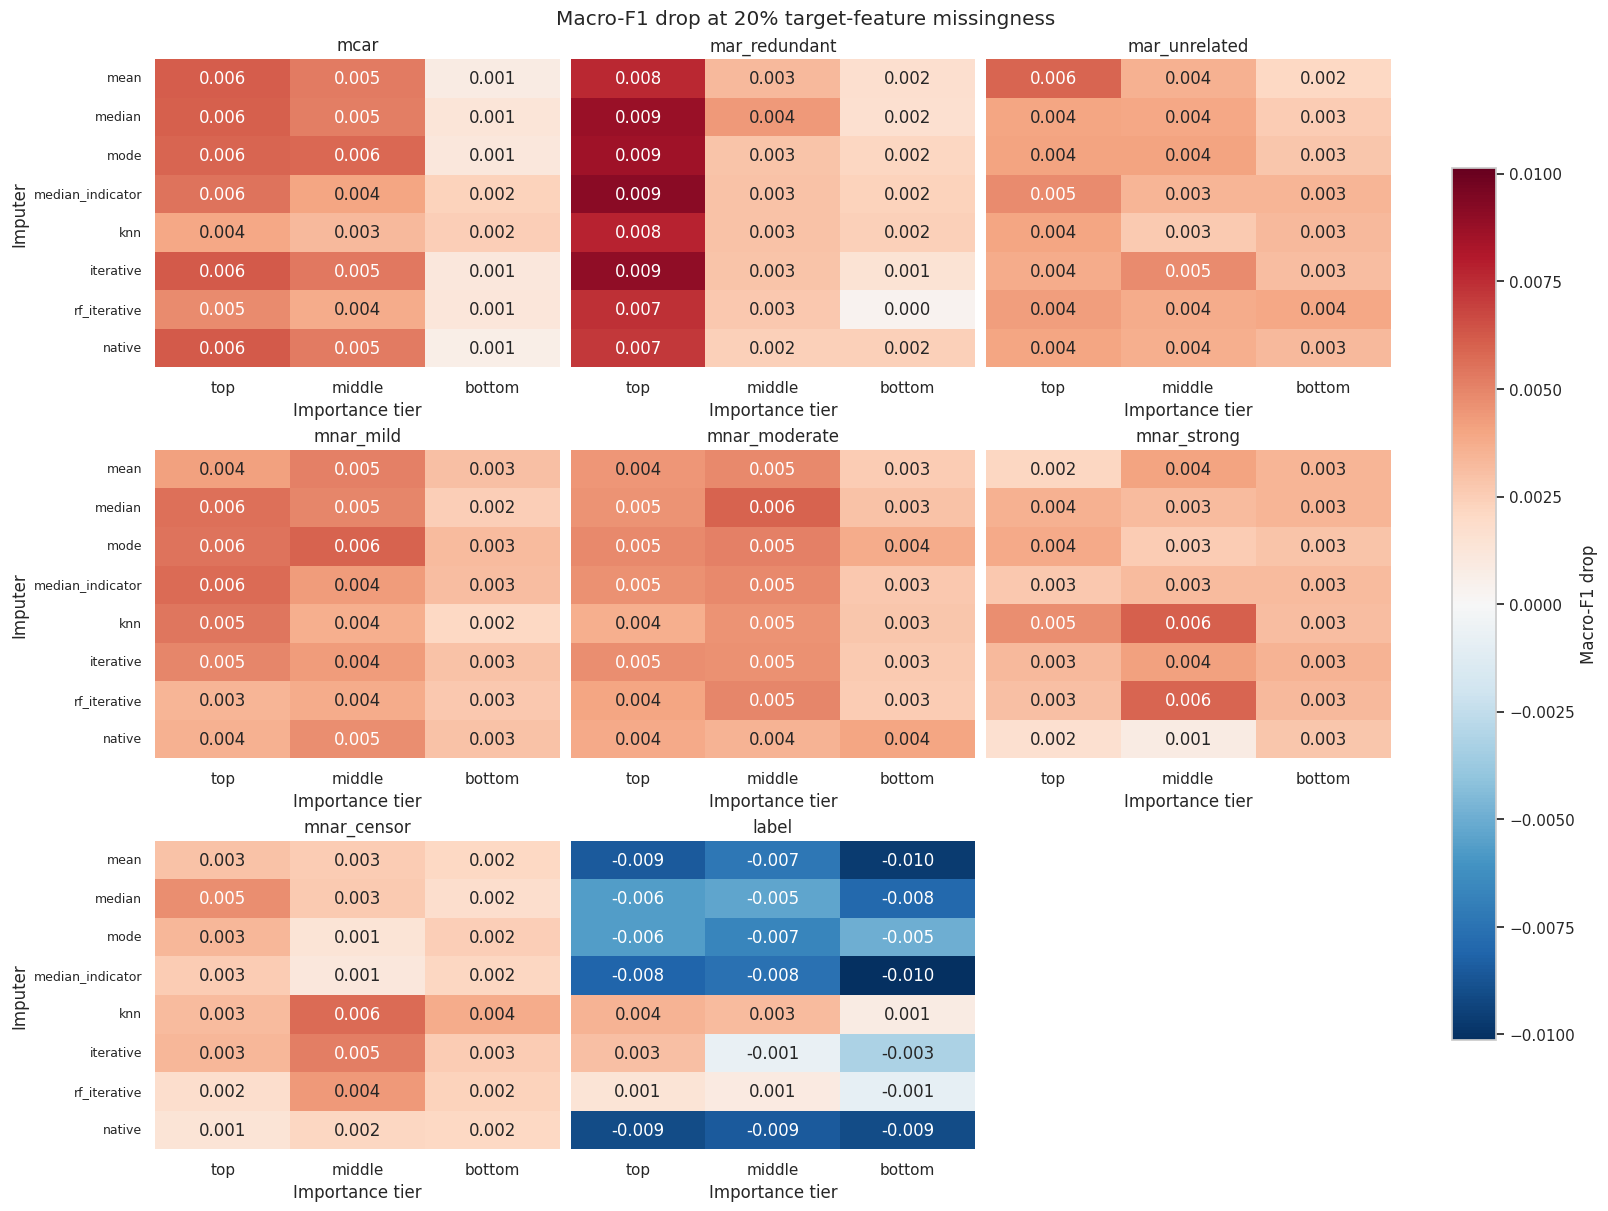

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


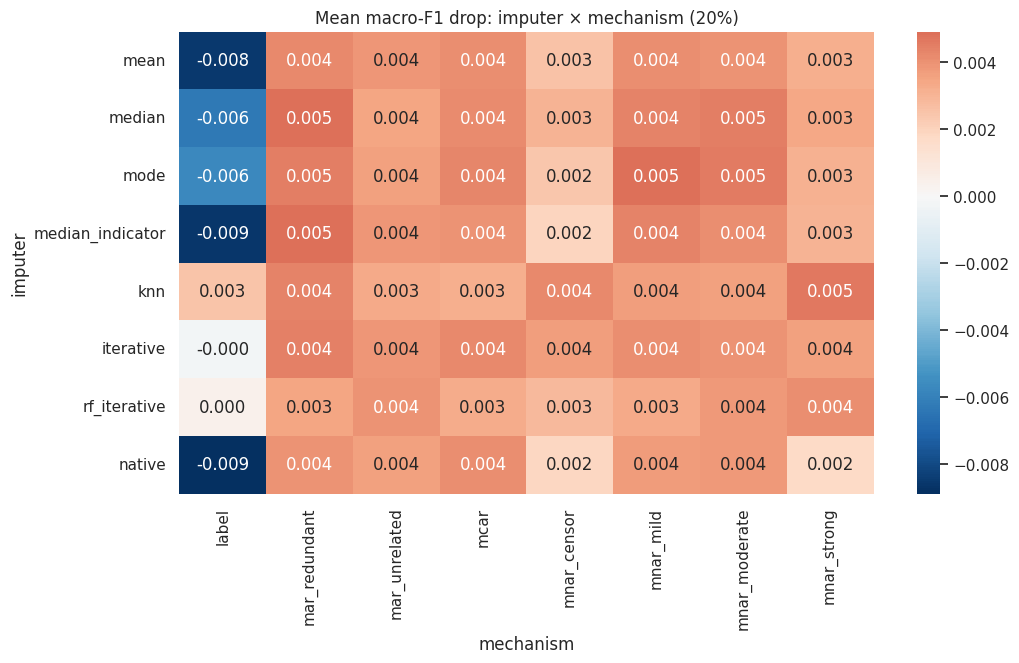

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


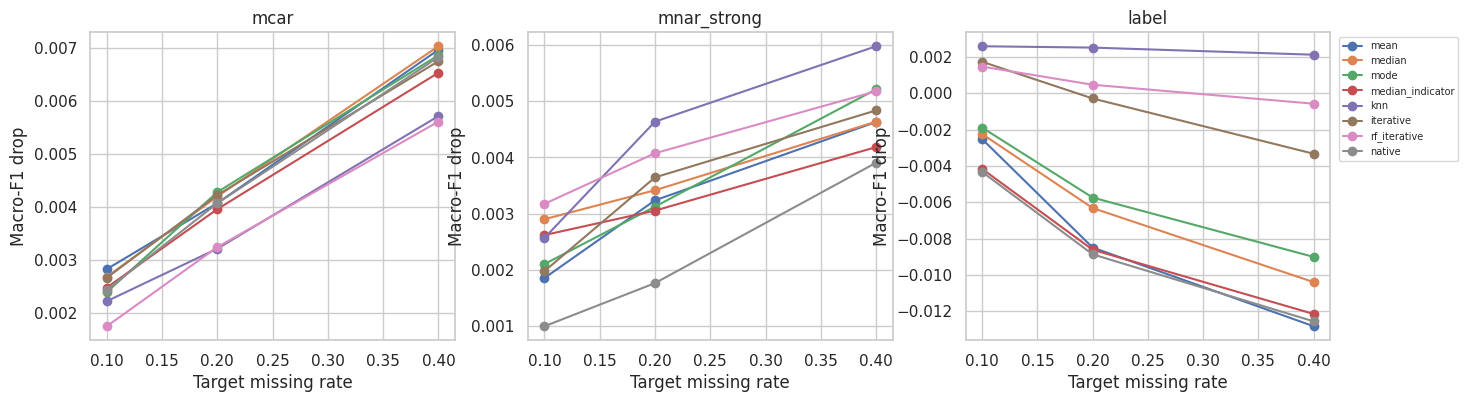

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


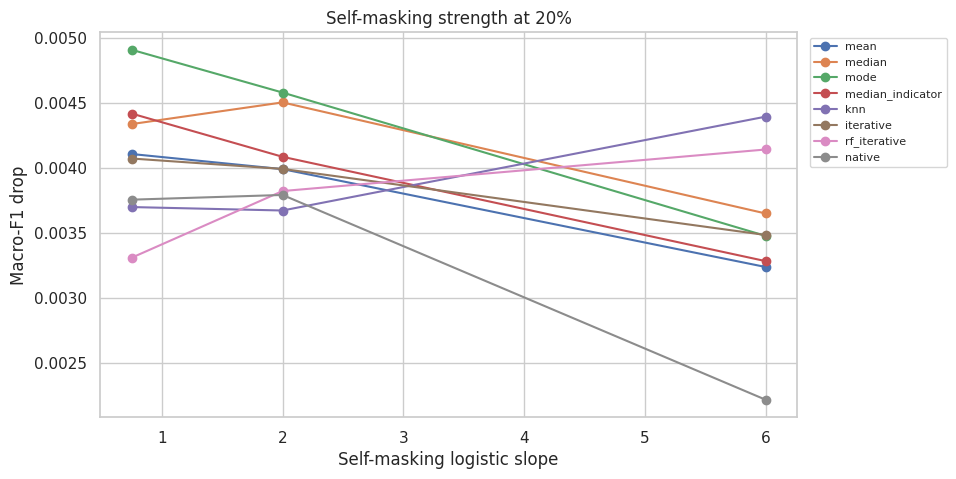

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


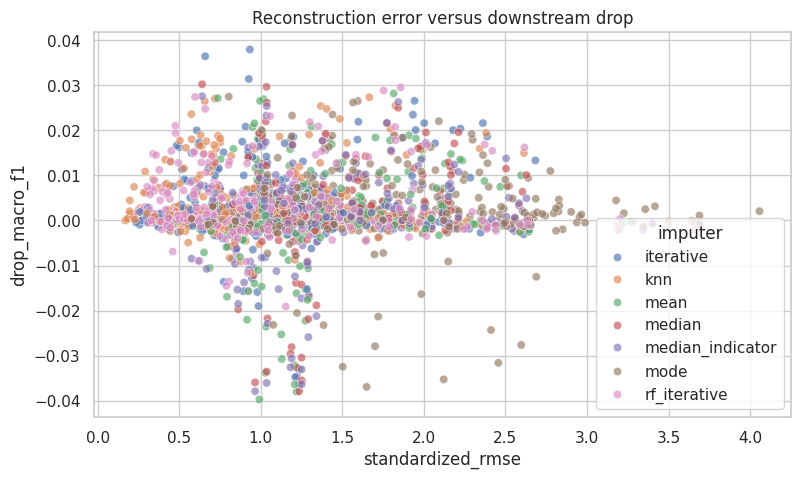

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,spearman_rho,descriptive_p,note
0,-0.011055,0.616204,"Dependent observations: p is descriptive, not ..."


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


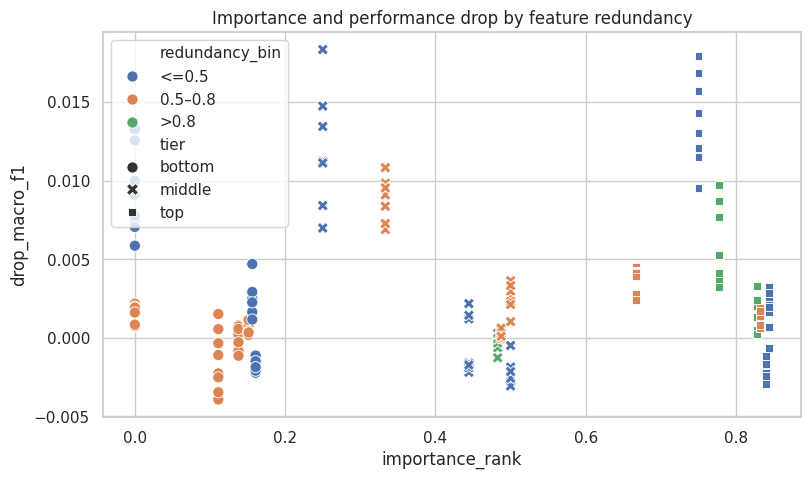

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


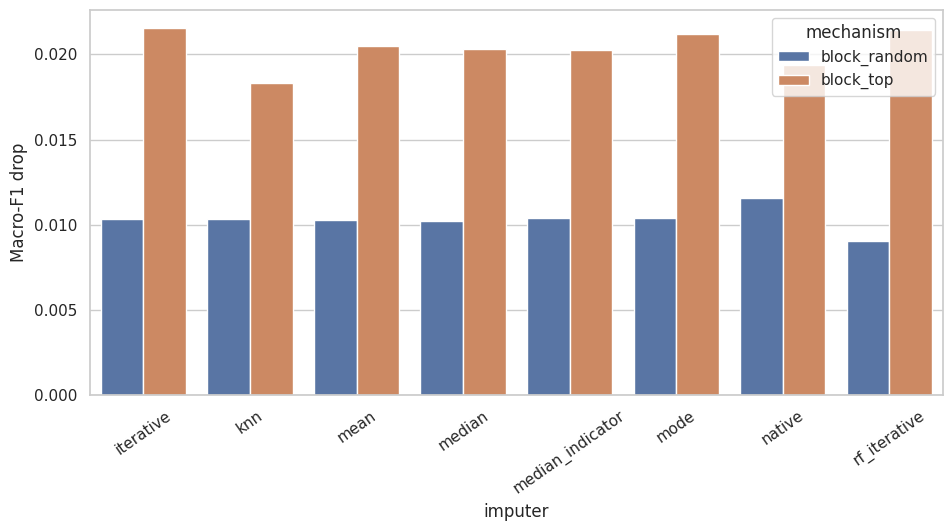

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


mechanism                                      label    mcar  mnar_strong
classifier importance_basis imputer                                      
hgb        permutation      iterative         0.0002  0.0011       0.0002
                            knn              -0.0003  0.0010       0.0031
                            mean              0.0003  0.0019      -0.0017
                            median            0.0014  0.0021      -0.0014
                            median_indicator -0.0005  0.0021      -0.0011
                            mode             -0.0023  0.0020      -0.0008
                            native           -0.0019  0.0019      -0.0021
                            rf_iterative     -0.0000  0.0012      -0.0000
lr         permutation      iterative         0.0072  0.0052       0.0036
                            knn               0.0003  0.0004       0.0006
                            mean              0.0108  0.0121       0.0132
                            median            0.0109  0.0128       0.0120
                            median_indicator  0.0015  0.0117       0.0008
                            mode              0.0038  0.0130       0.0206
                            rf_iterative      0.0013  0.0015       0.0027
mlp        permutation      iterative         0.0052  0.0036       0.0008
                            knn               0.0013  0.0010      -0.0002
                            mean              0.0052  0.0089       0.0023
                            median            0.0043  0.0084       0.0016
                            median_indicator  0.0022  0.0032      -0.0005
                            mode              0.0009  0.0055       0.0015
                            rf_iterative      0.0015  0.0017       0.0002
rf         permutation      iterative         0.0022  0.0044       0.0006
                            knn              -0.0009  0.0012       0.0006
                            mean              0.0016  0.0041       0.0003
                            median            0.0008  0.0047       0.0010
                            median_indicator  0.0014  0.0071       0.0008
                            mode              0.0009  0.0029       0.0001
                            rf_iterative      0.0009  0.0020       0.0001

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


mechanism                                      label    mcar  mnar_strong
classifier importance_basis imputer                                      
xgb        mi               iterative         0.0020  0.0026       0.0007
                            knn               0.0008  0.0003      -0.0005
                            mean              0.0009  0.0022       0.0006
                            median            0.0005  0.0012       0.0016
                            median_indicator  0.0021  0.0019       0.0007
                            mode              0.0010  0.0021       0.0006
                            native           -0.0002  0.0023      -0.0001
                            rf_iterative      0.0010  0.0013      -0.0001

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,scenario,imputer,mean,std,count
0,matched,iterative,0.005114,0.007264,5
1,matched,knn,0.003476,0.006187,5
2,matched,mean,0.004239,0.004459,5
3,matched,median,0.004313,0.003862,5
4,matched,median_indicator,0.005472,0.006717,5
5,matched,mode,0.004725,0.004464,5
6,matched,native,0.003124,0.005032,5
7,matched,rf_iterative,0.003175,0.007567,5
8,matched_label,iterative,0.001138,0.004634,5
9,matched_label,knn,0.001588,0.009245,5


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


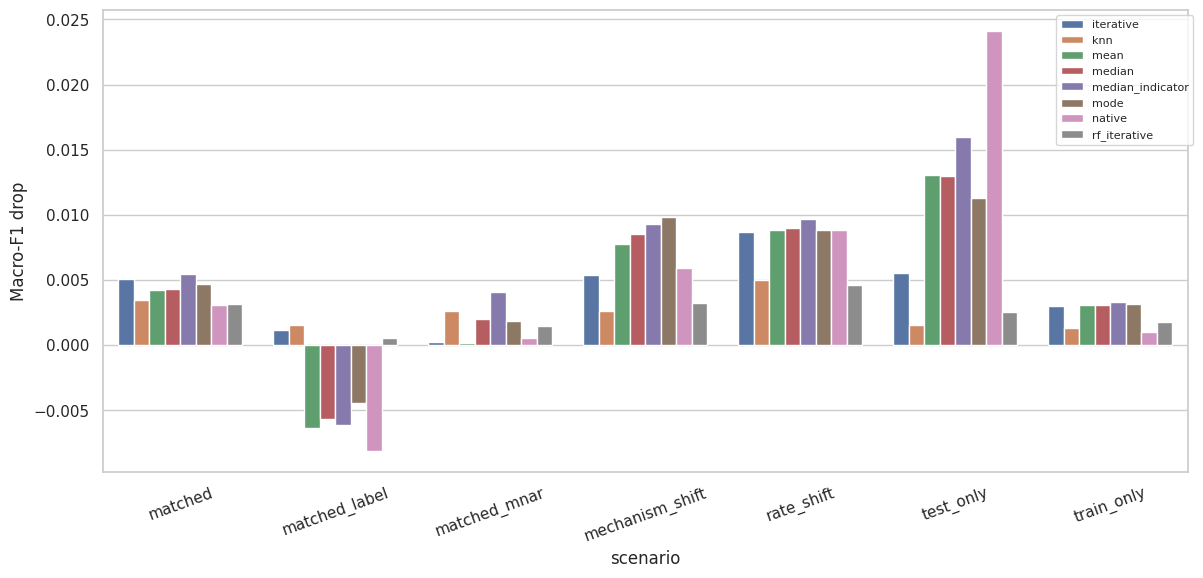

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


completion,ok
stage,
core,29568
importance_robustness,288
mismatch,840
multimodel,1044


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [13]:
FIGURES = OUT / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)

def show_figure(fig, name):
    """Export a named PNG/PDF figure, display it, and release plot memory."""
    for extension in ['png', 'pdf']:
        path = FIGURES / f'{name}.{extension}'
        temporary = path.with_suffix(path.suffix + '.tmp')
        fig.savefig(temporary, format=extension, dpi=300, bbox_inches='tight')
        os.replace(temporary, path)
    plt.show(); plt.close(fig)

def paired_complete(frame,methods=IMPUTERS):
    """Keep only settings with all requested methods, including matching fold/seed."""
    if frame.empty: return frame.copy()
    keys=[c for c in ['stage','dataset','fold','mask_seed','classifier','mechanism','rate',
                      'tier','importance_basis','scenario'] if c in frame.columns]
    chosen=frame[frame.imputer.isin(methods)].copy()
    counts=chosen.groupby(keys,dropna=False).imputer.transform('nunique')
    return chosen[counts==len(methods)].copy()

def equal_dataset_summary(frame,keys,value='drop_macro_f1'):
    if frame.empty: return pd.DataFrame()
    per=frame.groupby(['dataset',*keys],dropna=False)[value].mean().reset_index()
    return per.groupby(keys,dropna=False)[value].agg(['mean','std','count']).reset_index()

RESULTS=consolidate('results')
CORE=paired_complete(RESULTS[RESULTS.stage=='core']) if not RESULTS.empty else pd.DataFrame()
if not CORE.empty:
    SINGLE=CORE[CORE.tier!='block'].copy()
    TABLE=equal_dataset_summary(SINGLE,['mechanism','tier','rate','imputer'])
    keep('performance_summary',TABLE); display(TABLE.head(30))
    at20=SINGLE[np.isclose(SINGLE.rate,.2)]
    mechanisms=list(at20.mechanism.unique())
    fig,axes=plt.subplots(int(np.ceil(len(mechanisms)/3)),min(3,len(mechanisms)),
        figsize=(16,4*int(np.ceil(len(mechanisms)/3))),squeeze=False,constrained_layout=True)
    color_bound=max(1e-5,float(equal_dataset_summary(at20,['mechanism','imputer','tier'])['mean'].abs().max()))
    for index,(ax,m) in enumerate(zip(axes.flat,mechanisms)):
        tab=equal_dataset_summary(at20[at20.mechanism==m],['imputer','tier'])
        pivot=tab.pivot(index='imputer',columns='tier',values='mean').reindex(IMPUTERS)[['top','middle','bottom']]
        sns.heatmap(pivot,annot=True,fmt='.3f',cmap='RdBu_r',center=0,
                    vmin=-color_bound,vmax=color_bound,cbar=False,ax=ax)
        ax.set_title(m); ax.set_xlabel('Importance tier')
        ax.set_ylabel('Imputer' if index%axes.shape[1]==0 else '')
        if index%axes.shape[1]!=0: ax.set_yticklabels([])
        ax.tick_params(axis='y',labelsize=9)
    for ax in list(axes.flat)[len(mechanisms):]: ax.axis('off')
    fig.colorbar(plt.cm.ScalarMappable(norm=plt.Normalize(-color_bound,color_bound),cmap='RdBu_r'),
                 ax=list(axes.flat)[:len(mechanisms)],shrink=.8,label='Macro-F1 drop')
    fig.suptitle('Macro-F1 drop at 20% target-feature missingness')
    show_figure(fig,'drop_by_importance_and_mechanism')
    hm=equal_dataset_summary(at20,['imputer','mechanism']).pivot(index='imputer',columns='mechanism',values='mean').reindex(IMPUTERS)
    fig,ax=plt.subplots(figsize=(max(9,1.4*len(hm.columns)),6))
    sns.heatmap(hm,annot=True,fmt='.3f',cmap='RdBu_r',center=0,ax=ax)
    ax.set_title('Mean macro-F1 drop: imputer × mechanism (20%)'); show_figure(fig,'drop_by_mechanism')
    rates=equal_dataset_summary(SINGLE[SINGLE.mechanism.isin(['mcar','mnar_strong','label'])],['imputer','mechanism','rate'])
    fig,axes=plt.subplots(1,3,figsize=(16,4))
    for ax,m in zip(axes,['mcar','mnar_strong','label']):
        for method in IMPUTERS:
            q=rates[(rates.imputer==method)&(rates.mechanism==m)]
            if len(q): ax.plot(q.rate,q['mean'],marker='o',label=method)
        ax.set_title(m); ax.set_xlabel('Target missing rate'); ax.set_ylabel('Macro-F1 drop')
    axes[-1].legend(fontsize=7,bbox_to_anchor=(1.01,1)); show_figure(fig,'drop_by_rate')
    strong=SINGLE[SINGLE.mechanism.isin(STRENGTHS)].copy()
    strengths=equal_dataset_summary(strong,['imputer','mnar_strength'])
    fig,ax=plt.subplots(figsize=(9,5))
    for method in IMPUTERS:
        q=strengths[strengths.imputer==method].sort_values('mnar_strength')
        if len(q): ax.plot(q.mnar_strength,q['mean'],marker='o',label=method)
    ax.set(xlabel='Self-masking logistic slope',ylabel='Macro-F1 drop',title='Self-masking strength at 20%')
    ax.legend(bbox_to_anchor=(1.01,1),fontsize=8); show_figure(fig,'drop_by_mnar_strength')
    scatter=SINGLE.groupby(['dataset','imputer','mechanism','tier','rate'])[['standardized_rmse','drop_macro_f1']].mean().reset_index().dropna()
    fig,ax=plt.subplots(figsize=(9,5))
    sns.scatterplot(data=scatter,x='standardized_rmse',y='drop_macro_f1',hue='imputer',alpha=.65,ax=ax)
    ax.set(title='Reconstruction error versus downstream drop'); show_figure(fig,'rmse_vs_drop')
    if len(scatter)>3:
        rho,p=spearmanr(scatter.standardized_rmse,scatter.drop_macro_f1)
        display(keep('rmse_drop_association',pd.DataFrame([{'spearman_rho':rho,'descriptive_p':p,'note':'Dependent observations: p is descriptive, not independent-sample inference'}])))
    red=at20.groupby(['dataset','imputer','tier'])[['importance_rank','redundancy','drop_macro_f1']].mean().reset_index()
    red['redundancy_bin']=pd.cut(red.redundancy,[-.001,.5,.8,1.001],labels=['<=0.5','0.5–0.8','>0.8'])
    fig,ax=plt.subplots(figsize=(9,5))
    sns.scatterplot(data=red,x='importance_rank',y='drop_macro_f1',hue='redundancy_bin',style='tier',s=65,ax=ax)
    ax.set(title='Importance and performance drop by feature redundancy'); show_figure(fig,'redundancy_importance_drop')
    blocks=CORE[CORE.tier=='block']
    if not blocks.empty:
        b=equal_dataset_summary(blocks,['imputer','mechanism'])
        fig,ax=plt.subplots(figsize=(11,5)); sns.barplot(data=b,x='imputer',y='mean',hue='mechanism',ax=ax,errorbar=None)
        ax.tick_params(axis='x',rotation=35); ax.set_ylabel('Macro-F1 drop'); show_figure(fig,'block_missingness')
    for stage in ['multimodel','importance_robustness']:
        subset=RESULTS[RESULTS.stage==stage]
        if not subset.empty:
            tab=equal_dataset_summary(subset,['classifier','importance_basis','mechanism','tier','imputer'])
            keep(f'{stage}_summary',tab)
            display(tab.groupby(['classifier','importance_basis','mechanism','imputer'])['mean'].mean().unstack('mechanism').round(4))
if not MISMATCH.empty:
    mm=paired_complete(MISMATCH)
    if not mm.empty:
        mt=equal_dataset_summary(mm,['scenario','imputer'])
        keep('mismatch_summary',mt); display(mt)
        fig,ax=plt.subplots(figsize=(14,6))
        sns.barplot(data=mt,x='scenario',y='mean',hue='imputer',errorbar=None,ax=ax)
        ax.set_ylabel('Macro-F1 drop'); ax.tick_params(axis='x',rotation=20)
        ax.legend(bbox_to_anchor=(1.01,1),fontsize=8); show_figure(fig,'train_test_mismatch')
COVERAGE=update_coverage()
if not COVERAGE.empty: display(COVERAGE.groupby(['stage','completion']).size().unstack(fill_value=0))

## 10. Statistical Analysis

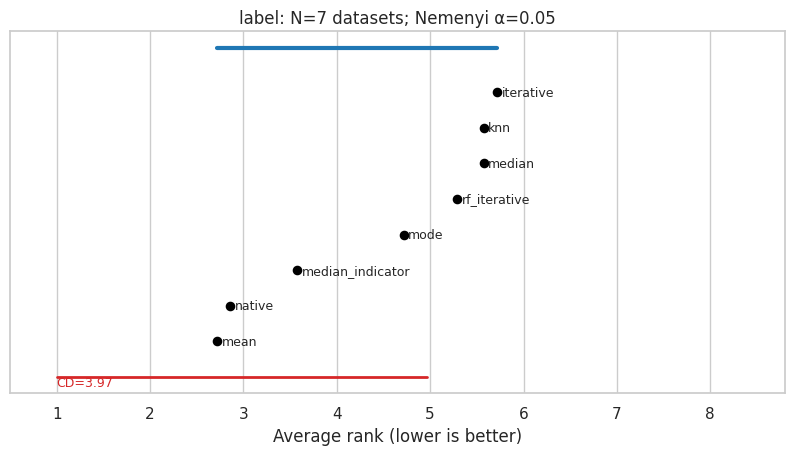

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


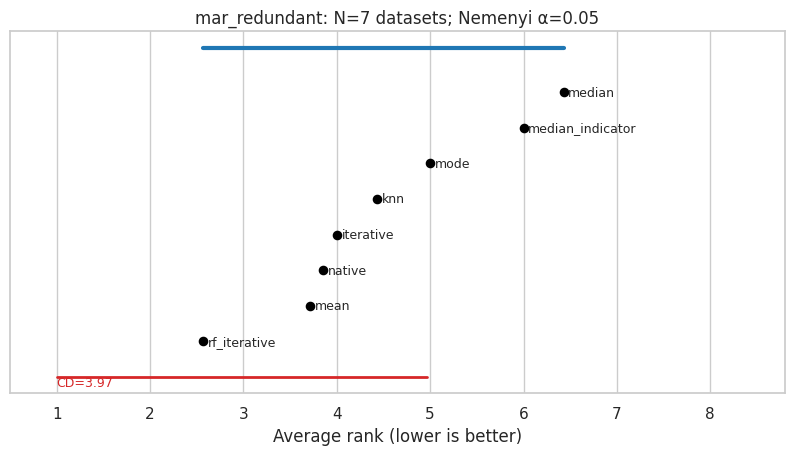

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


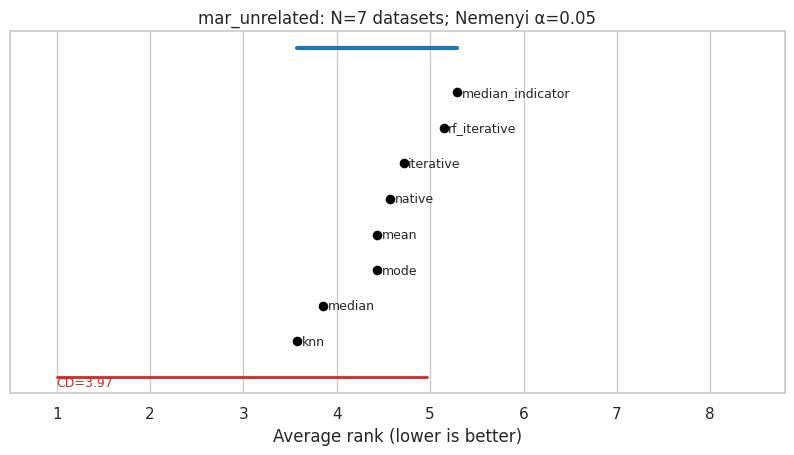

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


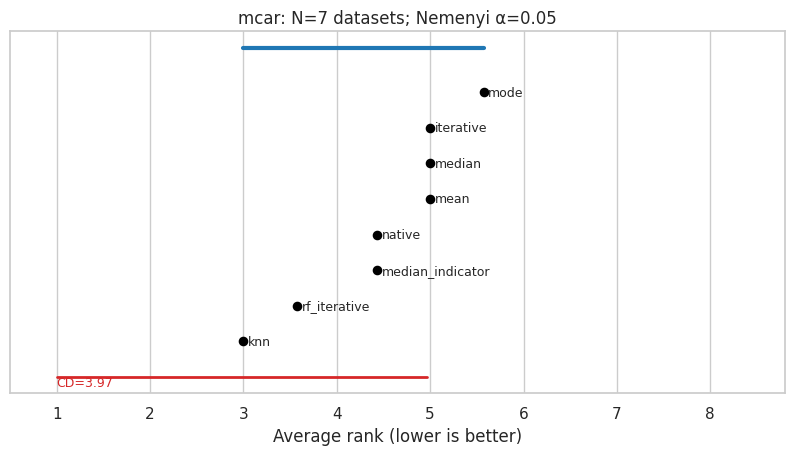

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


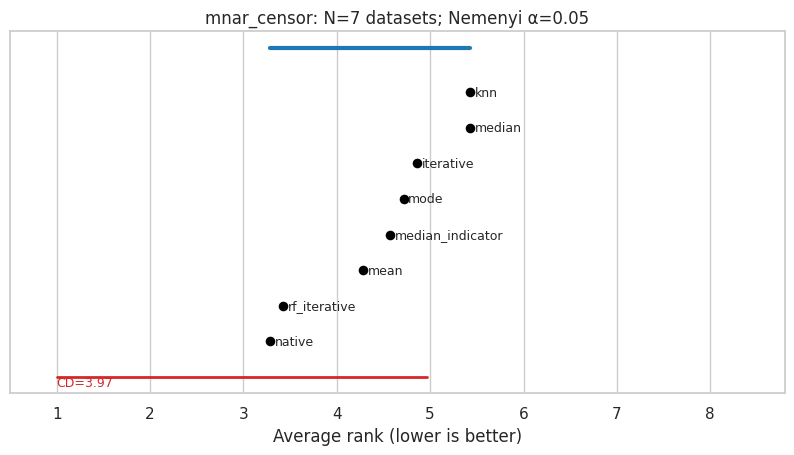

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


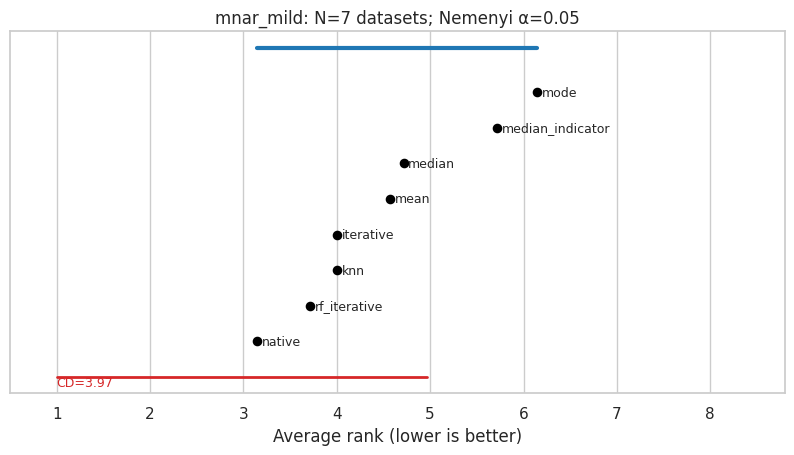

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


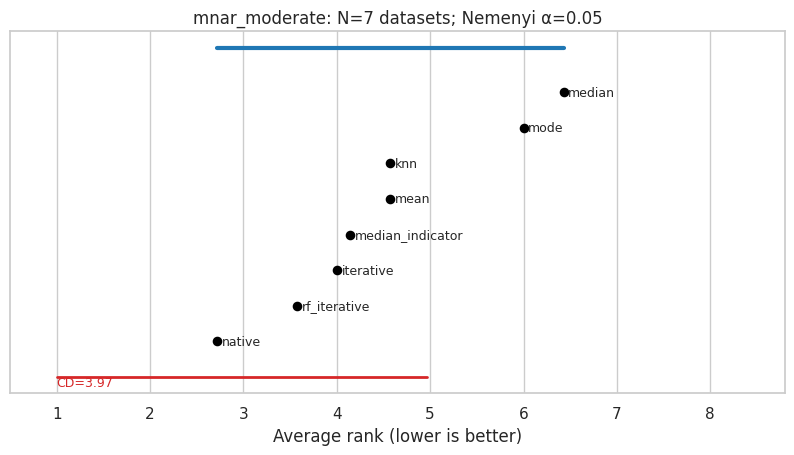

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


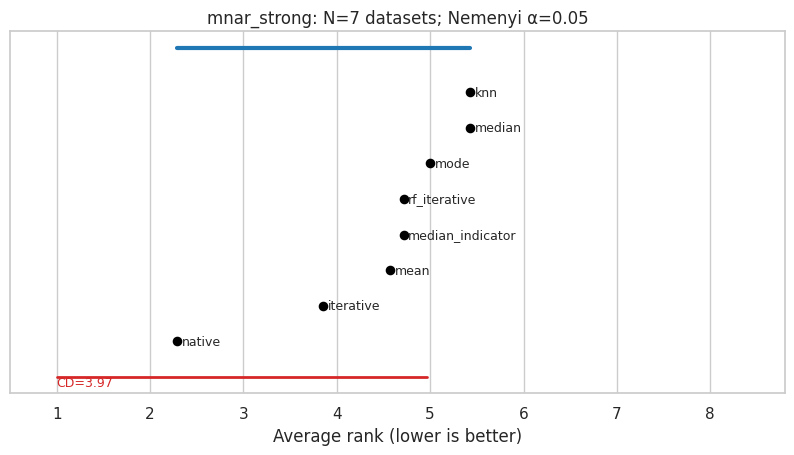

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


mechanism,label,mar_redundant,mar_unrelated,mcar,mnar_censor,mnar_mild,mnar_moderate,mnar_strong
imputer,,,,,,,,
mean,2.71,3.71,4.43,5.00,4.29,4.57,4.57,4.57
median,5.57,6.43,3.86,5.00,5.43,4.71,6.43,5.43
mode,4.71,5.00,4.43,5.57,4.71,6.14,6.00,5.00
median_indicator,3.57,6.00,5.29,4.43,4.57,5.71,4.14,4.71
knn,5.57,4.43,3.57,3.00,5.43,4.00,4.57,5.43
iterative,5.71,4.00,4.71,5.00,4.86,4.00,4.00,3.86
rf_iterative,5.29,2.57,5.14,3.57,3.43,3.71,3.57,4.71
native,2.86,3.86,4.57,4.43,3.29,3.14,2.71,2.29


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,note
0,No pairwise difference passed Holm-adjusted Wi...


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


...

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,term,coefficient,standard_error,ci_low,ci_high,p_exploratory,ci_method
0,Intercept,-0.011503,0.005349,-0.024593,0.001586,0.075066,dataset-cluster sandwich; small-cluster explor...
1,C(imputer)[T.knn],0.005660,0.004756,-0.005977,0.017296,0.278954,dataset-cluster sandwich; small-cluster explor...
2,C(imputer)[T.mean],-0.005335,0.002374,-0.011144,0.000473,0.065648,dataset-cluster sandwich; small-cluster explor...
3,C(imputer)[T.median],-0.004319,0.002851,-0.011294,0.002656,0.180529,dataset-cluster sandwich; small-cluster explor...
4,C(imputer)[T.median_indicator],-0.005812,0.002572,-0.012105,0.000480,0.064524,dataset-cluster sandwich; small-cluster explor...
5,C(imputer)[T.mode],-0.001579,0.003075,-0.009102,0.005944,0.625914,dataset-cluster sandwich; small-cluster explor...
6,C(imputer)[T.native],-0.005029,0.002250,-0.010534,0.000476,0.066787,dataset-cluster sandwich; small-cluster explor...
7,C(imputer)[T.rf_iterative],0.003873,0.003444,-0.004553,0.012300,0.303676,dataset-cluster sandwich; small-cluster explor...
8,C(mechanism)[T.mar_redundant],0.005584,0.003507,-0.002997,0.014165,0.162411,dataset-cluster sandwich; small-cluster explor...
9,C(mechanism)[T.mar_unrelated],0.009440,0.006083,-0.005445,0.024326,0.171691,dataset-cluster sandwich; small-cluster explor...


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,model,formula,datasets,observations,matrix_rank,columns,condition_number,rank_deficient,note
0,ols_primary,drop_macro_f1 ~ importance_rank * C(imputer) *...,7,2352,136,136,311.995946,False,Inference exploratory with few clusters; refer...
1,ols_moderation,drop_macro_f1 ~ importance_rank * C(imputer) *...,7,2352,144,144,319.446659,False,Inference exploratory with few clusters; refer...


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [14]:
def holm_adjust(pvalues):
    """Holm familywise correction, preserving order and NaNs."""
    p=np.array(pvalues,dtype=float); out=np.full(len(p),np.nan)
    valid=np.flatnonzero(np.isfinite(p)); order=valid[np.argsort(p[valid])]
    adjusted=np.maximum.accumulate((len(order)-np.arange(len(order)))*p[order])
    out[order]=np.minimum(adjusted,1.)
    return out

def bootstrap_mean(values,n=BOOTSTRAPS,seed=SEED):
    """Percentile interval over independent dataset-level effects."""
    v=np.asarray(values,dtype=float); v=v[np.isfinite(v)]
    if len(v)<2: return np.nan,np.nan,np.nan
    rng=np.random.default_rng(seed)
    means=v[rng.integers(0,len(v),size=(n,len(v)))].mean(axis=1)
    return float(v.mean()),float(np.quantile(means,.025)),float(np.quantile(means,.975))

def signed_test(v):
    v=np.asarray(v,float); v=v[np.isfinite(v)]
    if len(v)<3: return np.nan
    if np.allclose(v,0): return 1.
    try: return float(wilcoxon(v,alternative='two-sided',method='auto').pvalue)
    except ValueError: return np.nan

def cd_diagram(ranks,n,mechanism,cd):
    """Average-rank diagram with maximal Nemenyi nonsignificant cliques."""
    r=ranks.sort_values(); k=len(r)
    fig,ax=plt.subplots(figsize=(10,max(3,.4*k+1.5)))
    for i,(method,rank) in enumerate(r.items()):
        ax.scatter(rank,i,color='black',s=35); ax.text(rank+.05,i,method,va='center',fontsize=9)
    cliques=[]
    for start in range(k):
        end=start
        while end+1<k and r.iloc[end+1]-r.iloc[start]<=cd: end+=1
        if end>start: cliques.append((start,end))
    cliques=[c for c in cliques if not any(d!=c and d[0]<=c[0] and d[1]>=c[1] for d in cliques)]
    for row,(start,end) in enumerate(cliques):
        y=k+.25+.2*row; ax.plot([r.iloc[start],r.iloc[end]],[y,y],lw=3,color='tab:blue')
    ruler_y=-1.; x0=1.; ax.plot([x0,x0+cd],[ruler_y,ruler_y],lw=2,color='tab:red')
    ax.text(x0,ruler_y-.25,f'CD={cd:.2f}',color='tab:red',fontsize=9)
    ax.set_xlim(.5,max(k+.8,1+cd+.5)); ax.set_yticks([])
    ax.set_xlabel('Average rank (lower is better)')
    ax.set_title(f'{mechanism}: N={n} datasets; Nemenyi α={ALPHA}')
    show_figure(fig,f'critical_difference_{mechanism}')

FRIEDMAN=[]; POSTHOC=[]; RANKS=[]; BOOT_TABLE=[]
if not CORE.empty:
    singles=CORE[(CORE.tier!='block')&np.isclose(CORE.rate,.2)]
    for mechanism,part in singles.groupby('mechanism'):
        matrix=part.groupby(['dataset','imputer']).drop_macro_f1.mean().unstack().reindex(columns=IMPUTERS).dropna()
        if len(matrix)<3:
            FRIEDMAN.append({'mechanism':mechanism,'datasets':len(matrix),'status':'insufficient datasets'}); continue
        ranks=matrix.rank(axis=1,method='average').mean()
        try:
            stat,p=friedmanchisquare(*[matrix[c].values for c in matrix])
        except ValueError: stat,p=np.nan,np.nan
        k=len(matrix.columns); n=len(matrix)
        cd=float(studentized_range.ppf(1-ALPHA,k,np.inf)/np.sqrt(2)*np.sqrt(k*(k+1)/(6*n)))
        FRIEDMAN.append({'mechanism':mechanism,'datasets':n,'methods':k,'statistic':stat,'p':p,
                          'kendall_W':stat/(n*(k-1)),'critical_difference':cd,
                          'status':'exploratory' if FAST_MODE or n<MIN_INFERENCE_DATASETS else 'completed'})
        local=[]
        for a,b in combinations(matrix.columns,2):
            diff=matrix[a]-matrix[b]; effect,lo,hi=bootstrap_mean(diff)
            local.append({'mechanism':mechanism,'a':a,'b':b,'datasets':n,'p':signed_test(diff),
                          'drop_difference_a_minus_b':effect,'ci_low':lo,'ci_high':hi,
                          'paired_dz':float(diff.mean()/diff.std(ddof=1)) if diff.std(ddof=1)>0 else np.nan})
        adj=holm_adjust([r['p'] for r in local])
        for row,padj in zip(local,adj): row['p_holm']=padj; POSTHOC.append(row)
        RANKS.extend({'mechanism':mechanism,'imputer':m,'average_rank':float(r),'datasets':n} for m,r in ranks.items())
        cd_diagram(ranks,n,mechanism,cd)
    for (mechanism,method,tier),part in singles.groupby(['mechanism','imputer','tier']):
        v=part.groupby('dataset').drop_macro_f1.mean()
        mean,lo,hi=bootstrap_mean(v)
        BOOT_TABLE.append({'mechanism':mechanism,'imputer':method,'tier':tier,
                           'mean_drop':mean,'ci_low':lo,'ci_high':hi,'datasets':len(v)})
for name,rows in [('friedman',FRIEDMAN),('wilcoxon_holm',POSTHOC),('average_ranks',RANKS),('bootstrap_intervals',BOOT_TABLE)]:
    if rows: keep(name,pd.DataFrame(rows))
if RANKS:
    display(pd.DataFrame(RANKS).pivot(index='imputer',columns='mechanism',values='average_rank').reindex(IMPUTERS).round(2))
if POSTHOC:
    posthoc=pd.DataFrame(POSTHOC); significant=posthoc[posthoc.p_holm<ALPHA]
    display(significant if not significant.empty else pd.DataFrame([{'note':f'No pairwise difference passed Holm-adjusted Wilcoxon at alpha={ALPHA}'}]))
if FRIEDMAN:
    ft=pd.DataFrame(FRIEDMAN)
    if 'p' in ft: ft['p_holm_across_mechanisms']=holm_adjust(ft['p']); keep('friedman',ft)
    display(ft)

def build_numpy_design(frame,moderation=False):
    """Reference-coded OLS matrix matching the stated interaction formula."""
    levels={c:sorted(frame[c].unique()) for c in ['dataset','imputer','mechanism']}
    dummy={c:{v:(frame[c].to_numpy()==v).astype(float) for v in levels[c][1:]} for c in levels}
    rank=frame.importance_rank.to_numpy(float); red=frame.redundancy.to_numpy(float)
    arrays=[np.ones(len(frame)),rank,frame.rate.to_numpy(float),red]
    names=['Intercept','importance_rank','missing_rate','redundancy']
    for c in ['dataset','imputer','mechanism']:
        for level,v in dummy[c].items(): arrays.append(v); names.append(f'{c}[{level}]')
    for c in ['imputer','mechanism']:
        for level,v in dummy[c].items(): arrays.append(rank*v); names.append(f'importance_rank:{c}[{level}]')
    for im,iv in dummy['imputer'].items():
        for me,mv in dummy['mechanism'].items():
            arrays.extend([iv*mv,rank*iv*mv]); names.extend([f'imputer[{im}]:mechanism[{me}]',f'importance_rank:imputer[{im}]:mechanism[{me}]'])
    if moderation:
        arrays.append(rank*red); names.append('importance_rank:redundancy')
        for im,iv in dummy['imputer'].items():
            arrays.append(rank*red*iv); names.append(f'importance_rank:redundancy:imputer[{im}]')
    return np.column_stack(arrays),names

OLS_DIAGNOSTICS=[]
def fit_ols_report(frame,moderation=False):
    name='ols_moderation' if moderation else 'ols_primary'
    formula='drop_macro_f1 ~ importance_rank * C(imputer) * C(mechanism) + rate + redundancy + C(dataset)'
    if moderation: formula+=' + importance_rank:redundancy + importance_rank:redundancy:C(imputer)'
    try:
        if smf is not None:
            ordinary=smf.ols(formula,frame).fit()
            fit=ordinary.get_robustcov_results(cov_type='cluster',groups=frame.dataset,use_correction=True)
            ci=fit.conf_int(); names=fit.model.exog_names
            table=pd.DataFrame({'term':names,'coefficient':fit.params,'standard_error':fit.bse,
                                 'ci_low':ci[:,0],'ci_high':ci[:,1],'p_exploratory':fit.pvalues})
            condition=ordinary.condition_number; rank=np.linalg.matrix_rank(fit.model.exog); columns=fit.model.exog.shape[1]
        else:
            X,names=build_numpy_design(frame,moderation); y=frame.drop_macro_f1.to_numpy(float)
            beta=np.linalg.lstsq(X,y,rcond=None)[0]; residual=y-X@beta; bread=np.linalg.pinv(X.T@X)
            meat=np.zeros((X.shape[1],X.shape[1])); groups=frame.dataset.unique()
            for d in groups:
                use=frame.dataset.to_numpy()==d; score=X[use].T@residual[use]; meat+=np.outer(score,score)
            rank=np.linalg.matrix_rank(X); columns=X.shape[1]
            correction=len(groups)/max(1,len(groups)-1)*(len(y)-1)/max(1,len(y)-rank)
            se=np.sqrt(np.maximum(0,np.diag(correction*bread@meat@bread)))
            from scipy.stats import t as student_t
            critical=student_t.ppf(.975,max(1,len(groups)-1))
            table=pd.DataFrame({'term':names,'coefficient':beta,'standard_error':se,
                'ci_low':beta-critical*se,'ci_high':beta+critical*se,
                'p_exploratory':2*student_t.sf(np.abs(beta/np.maximum(se,1e-12)),max(1,len(groups)-1))})
            condition=np.linalg.cond(X)
        table['ci_method']='dataset-cluster sandwich; small-cluster exploratory'
        keep(f'{name}_coefficients',table)
        OLS_DIAGNOSTICS.append({'model':name,'formula':formula,'datasets':frame.dataset.nunique(),
            'observations':len(frame),'matrix_rank':rank,'columns':columns,'condition_number':condition,
            'rank_deficient':rank<columns,'note':'Inference exploratory with few clusters; reference-level terms depend on coding'})
        return table
    except Exception as e:
        log.warning('OLS failed: %s',e); OLS_DIAGNOSTICS.append({'model':name,'error':str(e)})
        return pd.DataFrame()

if not CORE.empty:
    regression=CORE[CORE.tier!='block'].groupby(['dataset','imputer','mechanism','tier','rate'])[
        ['drop_macro_f1','importance_rank','redundancy','redundancy_r2']].mean().reset_index()
    regression=regression.dropna(subset=['drop_macro_f1','importance_rank','redundancy'])
    PRIMARY_OLS=fit_ols_report(regression)
    MODERATION_OLS=fit_ols_report(regression,True)
    display(PRIMARY_OLS.head(12))
    display(keep('ols_diagnostics',pd.DataFrame(OLS_DIAGNOSTICS)))

## 11. Natural Missingness Validation

In [15]:
def run_natural():
    rows=[]
    for name,fold,method in product(GROUP_B,range(FOLDS*REPEATS),IMPUTERS):
        meta={'stage':'natural','dataset':name,'fold':fold,'classifier':MAIN_MODEL,'imputer':method}
        rows.append({'record_id':row_id(meta),**meta})
    keep('natural_plan',pd.DataFrame(rows))
    for row in tqdm(rows,desc='natural validation'):
        key=row['record_id']
        if key in table_cache('natural'): continue
        try:
            name,fold=row['dataset'],row['fold']; d=DATASETS[name]
            tr,te=cv_splits(name)[fold]; enc=FoldEncoder().fit(d['X'].iloc[tr])
            A=enc.transform(d['X'].iloc[tr]); B=enc.transform(d['X'].iloc[te]); y,z=d['y'][tr],d['y'][te]
            seed=stable_seed(SEED,name,fold,MAIN_MODEL)
            result=evaluate_method(row['imputer'],MAIN_MODEL,A,y,B,z,B,
                np.zeros_like(B,dtype=bool),enc,seed,stable_seed(SEED,name,fold,'natural_imputer'))
            result.update({**row,'train_missing_fraction':float(np.isnan(A).mean()),
                           'test_missing_fraction':float(np.isnan(B).mean()),'status':'ok'})
            write_record('natural',key,result); consolidate('natural')
        except Exception as e:
            log.warning('Natural validation failed: %s',str(e)[:200])
            write_record('errors',key,{**row,'error':str(e),'status':'failed'})
try:
    if RUN_NATURAL: run_natural()
finally:
    NATURAL = consolidate('natural', force=True)
    ARCHIVE = export_results('natural_validation')
    print('Saved result ZIP:', ARCHIVE)
if not NATURAL.empty:
    tab=NATURAL.groupby(['dataset','imputer'])[METRICS_HIGH+METRICS_LOW+['runtime_seconds']].mean().reset_index()
    counts=NATURAL.groupby(['dataset','imputer']).size().rename('completed_folds').reset_index()
    tab=tab.merge(counts,on=['dataset','imputer']); tab['planned_folds']=FOLDS*REPEATS
    keep('group_b_validation',tab); display(tab)
else:
    tab=pd.DataFrame([{'status':'unavailable','reason':'No completed Group B runs; attach Adult, Pima, or Horse Colic and check coverage.'}])
    keep('group_b_validation',tab); display(tab)
ARCHIVE = export_results('natural_validation')
print('Saved result ZIP:', ARCHIVE)


natural validation:   0%|          | 0/144 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Saved result ZIP: /kaggle/working/imputation_study_26ed27b95505.zip


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,dataset,imputer,accuracy,macro_f1,balanced_accuracy,roc_auc,minority_f1,brier,ece,runtime_seconds,completed_folds,planned_folds
0,adult,iterative,0.855333,0.792092,0.779811,0.916857,0.677527,0.099452,0.036218,0.166342,6,6
1,adult,knn,0.855333,0.792092,0.779811,0.916857,0.677527,0.099452,0.036218,0.157585,6,6
2,adult,mean,0.855333,0.792092,0.779811,0.916857,0.677527,0.099452,0.036218,0.165559,6,6
3,adult,median,0.855333,0.792092,0.779811,0.916857,0.677527,0.099452,0.036218,0.159844,6,6
4,adult,median_indicator,0.854333,0.791419,0.780097,0.915630,0.676970,0.099765,0.038847,0.158455,6,6
5,adult,mode,0.855333,0.792092,0.779811,0.916857,0.677527,0.099452,0.036218,0.159750,6,6
6,adult,native,0.856333,0.793030,0.780458,0.917665,0.678671,0.098985,0.037711,0.154227,6,6
7,adult,rf_iterative,0.855333,0.792092,0.779811,0.916857,0.677527,0.099452,0.036218,0.654744,6,6
8,credit_approval,iterative,0.861594,0.859814,0.860249,0.931286,0.844349,0.099198,0.063945,0.155553,6,6
9,credit_approval,knn,0.869565,0.867988,0.868709,0.933379,0.853879,0.095667,0.052240,0.150972,6,6


Saved result ZIP: /kaggle/working/imputation_study_26ed27b95505.zip


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 12. Effect Contrasts

In [16]:
def per_dataset_slopes(core):
    """Adjusted importance and redundancy slopes per independent dataset/method."""
    part=core[(core.tier!='block')&np.isclose(core.rate,.2)]
    part=part.groupby(['dataset','fold','imputer','mechanism','tier'])[
        ['drop_macro_f1','importance_rank','redundancy']].mean().reset_index()
    rows=[]
    for (dataset,method),g in part.groupby(['dataset','imputer']):
        rank=g.importance_rank.to_numpy(); red=g.redundancy.to_numpy(); red=red-red.mean()
        mech=pd.get_dummies(g.mechanism,drop_first=True,dtype=float).to_numpy()
        fold=pd.get_dummies(g.fold,drop_first=True,dtype=float).to_numpy()
        X=np.column_stack([np.ones(len(g)),rank,red,rank*red,mech,fold])
        rank_ok=np.linalg.matrix_rank(X)==X.shape[1]
        condition=np.linalg.cond(X)
        coef=np.linalg.lstsq(X,g.drop_macro_f1,rcond=None)[0]
        rows.append({'dataset':dataset,'imputer':method,
            'importance_slope':float(coef[1]) if rank_ok and condition<1e8 else np.nan,
            'moderation_slope':float(coef[3]) if rank_ok and condition<1e8 else np.nan,
            'estimable':rank_ok and condition<1e8,'condition_number':condition})
    return pd.DataFrame(rows)

CONTRAST_ROWS=[]; WINNER_SWITCHES=[]
def record_contrast(analysis,label,values,kind='difference'):
    values=pd.Series(values).dropna(); effect,lo,hi=bootstrap_mean(values)
    sd=values.std(ddof=1)
    CONTRAST_ROWS.append({'analysis':analysis,'contrast':label,'kind':kind,
        'datasets':len(values),'effect':effect,'ci_low':lo,'ci_high':hi,'p':signed_test(values),
        'paired_dz':float(values.mean()/sd) if sd>0 else np.nan})

if not CORE.empty:
    slopes=per_dataset_slopes(CORE); keep('dataset_slopes',slopes)
    slopes_a=slopes.pivot(index='dataset',columns='imputer',values='importance_slope')
    slopes_r=slopes.pivot(index='dataset',columns='imputer',values='moderation_slope')
    record_contrast('importance_slope','Mean adjusted importance slope',slopes_a.mean(axis=1),'positive')
    record_contrast('redundancy_moderation','Mean importance × redundancy slope',slopes_r.mean(axis=1),'moderation')
    for method in [m for m in IMPUTERS if m!='median']:
        if method in slopes_a and 'median' in slopes_a:
            record_contrast('method_importance_slope',f'{method} minus median: importance slope',slopes_a[method]-slopes_a['median'])
            record_contrast('method_redundancy_moderation',f'{method} minus median: moderation slope',slopes_r[method]-slopes_r['median'],'moderation')
    at20=CORE[(CORE.tier!='block')&np.isclose(CORE.rate,.2)]
    matrices={m:q.groupby(['dataset','imputer']).drop_macro_f1.mean().unstack().reindex(columns=IMPUTERS)
              for m,q in at20.groupby('mechanism')}
    for mechanism in ['label','mnar_strong']:
        if mechanism not in matrices: continue
        mat=matrices[mechanism]
        for method in ['median_indicator','native']:
            if method in mat and 'median' in mat:
                record_contrast('mechanism_advantage',f'{mechanism}: median minus {method} drop',mat['median']-mat[method],'positive_advantage')
        if 'mcar' in matrices:
            common=mat.index.intersection(matrices['mcar'].index)
            for method in [m for m in IMPUTERS if m!='median']:
                record_contrast('mechanism_shift_vs_mcar',f'{mechanism} versus MCAR: {method}-median change',
                    (mat.loc[common,method]-mat.loc[common,'median'])-
                    (matrices['mcar'].loc[common,method]-matrices['mcar'].loc[common,'median']))
    # Descriptive tier-winner switches, separate from formal interaction evidence.
    tier_matrix=at20.groupby(['dataset','tier','imputer']).drop_macro_f1.mean().unstack()
    for dataset in at20.dataset.unique():
        try:
            q=tier_matrix.loc[dataset]
            WINNER_SWITCHES.append({'analysis':'tier_winner_switch','dataset':dataset,
                'reference_winner':q.loc['bottom'].idxmin(),'comparison':'top',
                'comparison_winner':q.loc['top'].idxmin(),
                'switched':q.loc['bottom'].idxmin()!=q.loc['top'].idxmin()})
        except KeyError: pass
if not MISMATCH.empty:
    mm=paired_complete(MISMATCH)
    if not mm.empty:
        matrices={s:q.groupby(['dataset','imputer']).drop_macro_f1.mean().unstack().reindex(columns=IMPUTERS)
                  for s,q in mm.groupby('scenario')}
        reference=matrices.get('matched')
        if reference is not None:
            for scenario in ['train_only','test_only','rate_shift','mechanism_shift']:
                if scenario not in matrices: continue
                q=matrices[scenario]; common=q.index.intersection(reference.index)
                for dataset in common:
                    WINNER_SWITCHES.append({'analysis':'mismatch_winner_switch','dataset':dataset,
                        'reference_winner':reference.loc[dataset].idxmin(),'comparison':scenario,
                        'comparison_winner':q.loc[dataset].idxmin(),
                        'switched':reference.loc[dataset].idxmin()!=q.loc[dataset].idxmin()})
                for method in [m for m in IMPUTERS if m!='median']:
                    record_contrast('mismatch_shift',f'{scenario} versus matched: {method}-median change',
                        (q.loc[common,method]-q.loc[common,'median'])-
                        (reference.loc[common,method]-reference.loc[common,'median']))
if CONTRAST_ROWS:
    CONTRASTS=pd.DataFrame(CONTRAST_ROWS); CONTRASTS['p_holm']=holm_adjust(CONTRASTS['p'])
    CONTRASTS['practical']=CONTRASTS.effect.abs()>=PRACTICAL_DROP
    keep('effect_contrasts',CONTRASTS); display(CONTRASTS)
else: CONTRASTS=pd.DataFrame()
if WINNER_SWITCHES: display(keep('winner_switches',pd.DataFrame(WINNER_SWITCHES)))
COVERAGE=update_coverage()


,analysis,contrast,kind,datasets,effect,ci_low,ci_high,p,paired_dz,p_holm,practical
0,importance_slope,Mean adjusted importance slope,positive,7,0.005347,0.000204,0.013045,0.218750,0.538678,1.00000,False
1,redundancy_moderation,Mean importance × redundancy slope,moderation,7,-0.064705,-0.205124,0.012268,1.000000,-0.356064,1.00000,True
2,method_importance_slope,mean minus median: importance slope,difference,7,-0.001187,-0.002869,0.000272,0.468750,-0.505918,1.00000,False
3,method_redundancy_moderation,mean minus median: moderation slope,moderation,7,-0.004232,-0.019488,0.013143,0.296875,-0.183932,1.00000,False
4,method_importance_slope,mode minus median: importance slope,difference,7,-0.003521,-0.007229,-0.000619,0.031250,-0.706677,1.00000,False
5,method_redundancy_moderation,mode minus median: moderation slope,moderation,7,0.034959,-0.001467,0.100016,0.375000,0.417256,1.00000,True
6,method_importance_slope,median_indicator minus median: importance slope,difference,7,-0.001519,-0.002956,0.000026,0.156250,-0.686199,1.00000,False
7,method_redundancy_moderation,median_indicator minus median: moderation slope,moderation,7,0.016341,-0.000933,0.036370,0.156250,0.600619,1.00000,True
8,method_importance_slope,knn minus median: importance slope,difference,7,-0.004219,-0.009690,0.000137,0.109375,-0.581758,1.00000,False
9,method_redundancy_moderation,knn minus median: moderation slope,moderation,7,0.019845,-0.014410,0.063631,0.937500,0.341226,1.00000,True


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,analysis,dataset,reference_winner,comparison,comparison_winner,switched
0,tier_winner_switch,breast_cancer,median_indicator,top,rf_iterative,True
1,tier_winner_switch,banknote,native,top,rf_iterative,True
2,tier_winner_switch,digits,mean,top,native,True
3,tier_winner_switch,spambase,iterative,top,native,True
4,tier_winner_switch,magic,mean,top,median,True
5,tier_winner_switch,ionosphere,native,top,mean,True
6,tier_winner_switch,phoneme,median_indicator,top,native,True
7,mismatch_winner_switch,banknote,knn,train_only,iterative,True
8,mismatch_winner_switch,breast_cancer,knn,train_only,knn,False
9,mismatch_winner_switch,digits,rf_iterative,train_only,rf_iterative,False


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 13. Run Summary and ZIP Export


In [17]:
for table in ['results','baselines','mask_checks','mismatch','mismatch_mask_checks','natural','errors']:
    consolidate(table, force=True)
COVERAGE=update_coverage()
importance_frames=[frame for frame,_ in STATE['importance'].values()]
if importance_frames: keep('feature_importance',pd.concat(importance_frames,ignore_index=True))
RUN_SUMMARY={'run_id':RUN_ID,'gpu_info':gpu_info.stdout.strip() if NVIDIA_AVAILABLE else 'CPU',
    'torch_device':TORCH_DEVICE,'elapsed_seconds':round(time.monotonic()-START_TIME,1),
    'versions':VERSIONS,'primary_classifier':MAIN_MODEL,'group_a':GROUP_A,'group_b':GROUP_B,
    'fast_mode':FAST_MODE,'execution_time_limit':'none','output_directory':str(OUT),'exported_tables':sorted(TABLES)}
print(json.dumps(RUN_SUMMARY,indent=2,default=str))
if not COVERAGE.empty: display(COVERAGE.groupby(['stage','completion']).size().unstack(fill_value=0))
if not kept('errors').empty: display(kept('errors').head(20))

atomic_json(RUN_SUMMARY, OUT / 'run_summary.json')
ARCHIVE = export_results('run_summary')
print('Result ZIP:', ARCHIVE)
display(FileLink(str(ARCHIVE)))


{
  "run_id": "26ed27b95505",
  "gpu_info": "Tesla T4, 15360 MiB\nTesla T4, 15360 MiB",
  "torch_device": "cuda",
  "elapsed_seconds": 12082.9,
  "versions": {
    "python": "3.13.15",
    "numpy": "2.1.3",
    "pandas": "2.3.3",
    "scipy": "1.16.3",
    "sklearn": "1.6.1",
    "xgboost": "3.4.1",
    "torch": "2.11.0+cu128",
    "statsmodels": "0.15.0"
  },
  "primary_classifier": "xgb",
  "group_a": [
    "breast_cancer",
    "banknote",
    "digits",
    "spambase",
    "magic",
    "ionosphere",
    "phoneme"
  ],
  "group_b": [
    "adult",
    "horse",
    "credit_approval"
  ],
  "fast_mode": false,
  "execution_time_limit": "none",
  "output_directory": "/kaggle/working/study_results/26ed27b95505",
  "exported_tables": [
    "average_ranks",
    "baselines",
    "bootstrap_intervals",
    "coverage",
    "dataset_audit",
    "dataset_slopes",
    "dataset_summary",
    "effect_contrasts",
    "errors",
    "feature_importance",
    "friedman",
    "group_b_validation",
    "i

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


completion,ok
stage,
core,29568
importance_robustness,288
mismatch,840
multimodel,1044
natural,144


Result ZIP: /kaggle/working/imputation_study_26ed27b95505.zip


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


/kaggle/working/imputation_study_26ed27b95505.zip

## 14. Key Findings and Final ZIP


In [18]:
def key_findings():
    """Render measured results and limitations exclusively from the in-memory result tables."""
    results=kept('results'); coverage=kept('coverage')
    lines=['# Key findings',f'Run `{RUN_ID}`; primary classifier: `{MAIN_MODEL}`; mode: '+('FAST' if FAST_MODE else 'FULL')+'.']
    if not coverage.empty:
        total=len(coverage); completed=int((coverage.completion=='ok').sum())
        lines.append(f'Coverage: {completed}/{total} planned evaluations completed ({completed/max(total,1):.1%}).')
    if results.empty:
        lines.append('No predictive results were completed; no conclusion can be drawn.')
    else:
        primary=paired_complete(results[results.stage=='core'])
        if not primary.empty:
            primary=primary[(primary.tier!='block')&np.isclose(primary.rate,.2)]
            table=equal_dataset_summary(primary,['mechanism','imputer'])
            if not table.empty:
                lines.append('Empirical lowest macro-F1 drop at 20% target-feature missingness (averaged equally over datasets):')
                for mechanism,group in table.groupby('mechanism'):
                    best=group.loc[group['mean'].idxmin()]
                    lines.append(f'- {mechanism}: {best.imputer}; mean drop {best["mean"]:.4f}, N={int(best["count"])} datasets. Winner uncertainty remains.')
                overall=equal_dataset_summary(primary,['imputer']).sort_values('mean')
                if not overall.empty:
                    best=overall.iloc[0]
                    lines.append(f'Observed overall best: {best.imputer}, mean drop {best["mean"]:.4f}. Validate the method on the expected observation process; this aggregate does not establish a universal winner.')
        times=results.groupby('imputer').runtime_seconds.median().sort_values()
        lines.append('Median measured imputation+training+prediction runtime per evaluation: '+', '.join(f'{m} {s:.2f}s' for m,s in times.items())+'.')
    mismatch=kept('mismatch_summary')
    if not mismatch.empty:
        lines.append('Mismatch-specific empirical choices:')
        for scenario,group in mismatch.groupby('scenario'):
            best=group.loc[group['mean'].idxmin()]
            lines.append(f'- {scenario}: {best.imputer}, mean drop {best["mean"]:.4f}. See mismatch_shift rows in effect_contrasts.csv for uncertainty.')
    reconstruction=kept('rmse_drop_association')
    if not reconstruction.empty:
        lines.append(f'Reconstruction/downstream Spearman association: {reconstruction.spearman_rho.iloc[0]:.3f} (descriptive dependent observations). Select by held-out predictive performance; reconstruction error alone is not a selection criterion.')
    natural=kept('group_b_validation')
    if not natural.empty and 'macro_f1' in natural:
        lines.append(f'Natural-missingness validation: {natural.dataset.nunique()} dataset(s); complete-data drops and true imputation RMSE are unavailable.')
    else: lines.append('Natural-missingness validation is unavailable in this run.')
    sensitivity=kept('importance_robustness_summary')
    if sensitivity.empty: lines.append('MI target-selection robustness was not completed in this run.')
    lines.append('Interpretation limits: model-relative importance, fixed hyperparameters, finite datasets, row caps, simulation assumptions, and small-cluster inference. Negative drops are retained. Null and unfinished results are reported without favorable assumptions.')
    return '\n\n'.join(lines)

FINDINGS=key_findings()
display(Markdown(FINDINGS))

(OUT / 'key_findings.md').write_text(FINDINGS, encoding='utf-8')
ARCHIVE = export_results('final')
print('Final result ZIP:', ARCHIVE)
display(FileLink(str(ARCHIVE)))


# Key findings

Run `26ed27b95505`; primary classifier: `xgb`; mode: FULL.

Coverage: 31884/31884 planned evaluations completed (100.0%).

Empirical lowest macro-F1 drop at 20% target-feature missingness (averaged equally over datasets):

- label: native; mean drop -0.0089, N=7 datasets. Winner uncertainty remains.

- mar_redundant: rf_iterative; mean drop 0.0035, N=7 datasets. Winner uncertainty remains.

- mar_unrelated: knn; mean drop 0.0033, N=7 datasets. Winner uncertainty remains.

- mcar: knn; mean drop 0.0032, N=7 datasets. Winner uncertainty remains.

- mnar_censor: native; mean drop 0.0019, N=7 datasets. Winner uncertainty remains.

- mnar_mild: rf_iterative; mean drop 0.0033, N=7 datasets. Winner uncertainty remains.

- mnar_moderate: knn; mean drop 0.0037, N=7 datasets. Winner uncertainty remains.

- mnar_strong: native; mean drop 0.0018, N=7 datasets. Winner uncertainty remains.

Observed overall best: native, mean drop 0.0018. Validate the method on the expected observation process; this aggregate does not establish a universal winner.

Median measured imputation+training+prediction runtime per evaluation: native 0.14s, mean 0.14s, median 0.14s, median_indicator 0.14s, mode 0.15s, iterative 0.15s, knn 0.16s, rf_iterative 0.84s.

Mismatch-specific empirical choices:

- matched: native, mean drop 0.0031. See mismatch_shift rows in effect_contrasts.csv for uncertainty.

- matched_label: native, mean drop -0.0081. See mismatch_shift rows in effect_contrasts.csv for uncertainty.

- matched_mnar: mean, mean drop 0.0002. See mismatch_shift rows in effect_contrasts.csv for uncertainty.

- mechanism_shift: knn, mean drop 0.0027. See mismatch_shift rows in effect_contrasts.csv for uncertainty.

- rate_shift: rf_iterative, mean drop 0.0046. See mismatch_shift rows in effect_contrasts.csv for uncertainty.

- test_only: knn, mean drop 0.0015. See mismatch_shift rows in effect_contrasts.csv for uncertainty.

- train_only: native, mean drop 0.0010. See mismatch_shift rows in effect_contrasts.csv for uncertainty.

Reconstruction/downstream Spearman association: -0.011 (descriptive dependent observations). Select by held-out predictive performance; reconstruction error alone is not a selection criterion.

Natural-missingness validation: 3 dataset(s); complete-data drops and true imputation RMSE are unavailable.

Interpretation limits: model-relative importance, fixed hyperparameters, finite datasets, row caps, simulation assumptions, and small-cluster inference. Negative drops are retained. Null and unfinished results are reported without favorable assumptions.

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Final result ZIP: /kaggle/working/imputation_study_26ed27b95505.zip


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


/kaggle/working/imputation_study_26ed27b95505.zip

In [19]:
from pathlib import Path
from html import escape
from IPython.display import display, HTML, FileLink
import uuid

# Uses the ZIP created by the notebook's export cell.
zip_path = Path(ARCHIVE)

if not zip_path.is_file():
    raise FileNotFoundError(
        f"ZIP not found: {zip_path}. Execute the export cell first."
    )

link_id = "zip_download_" + uuid.uuid4().hex

link_html = FileLink(str(zip_path))._repr_html_()
link_html = link_html.replace(
    "<a ",
    f'<a id="{link_id}" download="{escape(zip_path.name, quote=True)}" ',
    1
)
link_html = link_html.replace("target='_blank'", "")
link_html = link_html.replace('target="_blank"', "")

display(HTML(f"""
<p><b>Results ZIP ready.</b>
If downloading does not start, click the link below.</p>
{link_html}
<script>
setTimeout(() => {{
    const link = document.getElementById("{link_id}");
    if (link) link.click();
}}, 500);
</script>
"""))